# DDI GNN Model — v24 (fixed, runs top-to-bottom without crashing)

v24 is v23 with every crash and silent bug fixed. The data pipeline, negatives, splits, metrics and PairNet architecture are unchanged, so results stay comparable.

## Fixes in v24 (vs the v23 file you uploaded)

| # | Problem in v23 | Effect | Fix |
|---|---|---|---|
| 1 | `DEGREE_MATCHED_NEGATIVES` was used in the training cell's cache signature but never defined (the negatives cell was switched to uniform sampling) | **`NameError` — the training cell crashed before training anything**, which is why the later cells (`V23_RESULTS`, `V23_COLD`) were "not defined" | Flag defined in the negatives cell (`False` = uniform sampling, as actually used) |
| 2 | Cold-start print block was dedented out of its `for` loop | `NameError` / printed only the last seed using leaked variables | Print moved inside the loop; one clean summary table afterwards |
| 3 | `CFG_B` referenced when `RUN_B=True` but never defined | `NameError` if B was switched on | `CFG_B` defined |
| 4 | Descriptor normalisation stats lived in the global `D.desc`, overwritten by the **last** `train_pair` call (the cold runs) | The saved / served model was evaluated with the wrong descriptor scaling -> silently wrong predictions in `predict_full_v24` | Mean/std are stored per trained model, saved in the `.pkl`, and re-applied before inference |
| 5 | `best_state` could stay `None` (NaN validation score) | `load_state_dict(None)` crash | NaN-safe best-model tracking in `train_pair` and `fit_clinical_action_probe` |
| 6 | Cold loop only allowed a variant literally named `'Structure + descriptors'` | Any other variant was silently skipped | Loop works for every variant |
| 7 | Best-model picker preferred names starting with `'D'` (no such variant exists any more) | Fell back by accident | Picks the best validation score among the variants that were trained |
| 8 | `QUICK_V23` flag was never read; header said 150 epochs, code ran 30 | Misleading | Flag now drives epochs (`QUICK`: 30 warm / 25 cold, full: 150 / 60) |
| 9 | Hard-coded Colab paths, `!pip`, `google.colab` import | Crash outside Colab; hard-coded `/content/drive/...` in 3 diagnostic cells | Paths come from `DRIVE_DATA_DIR` / `DRIVE_OUTPUT_DIR`; Drive mount and `pip` are optional |
| 10 | Debug cells that ran before training and printed "V23_COLD not defined"; empty cell; duplicate result cells | Noise | Removed or moved after training and guarded |
| 11 | Missing input files / empty side-effect coverage only failed deep inside later cells | Hard-to-read tracebacks | Up-front file check and clear error messages |

## What this notebook does

Data prep -> molecular graphs -> pair dataset with true negatives -> warm and drug-disjoint (cold) splits -> shortcut baseline (no chemistry) -> `PairNet` (GATv2 + Morgan fingerprint + RDKit descriptors, symmetric pair encoder) -> clinical action head -> calibration, bootstrap CIs -> saves `ddi_v24_best.pkl` -> `predict_full_v24(drug_a, drug_b)`.

**External dependency:** `merged_side_effect_terms.csv` in `DRIVE_OUTPUT_DIR`. If missing, the notebook falls back to SIDER only and prints a loud warning.


## Cell 1 — Paths (Colab/Drive optional)

On Colab the notebook mounts Drive and uses the paths below. Elsewhere it uses local folders, or the folders in the environment variables `DDI_DATA_DIR` / `DDI_OUTPUT_DIR`. Required files in the data folder: `ddis.csv`, `drug_smiles.csv`, and `meddra_all_se.tsv` (only needed if `merged_side_effect_terms.csv` is absent).


In [1]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False

# vvv UPDATE THIS to the folder containing ddis.csv, drug_smiles.csv, meddra_all_se.tsv
_default_data = '/content/drive/MyDrive/Colab Notebooks/pro/datasets' if IN_COLAB else './datasets'
_default_out = '/content/drive/MyDrive/Colab Notebooks/pro/my_ml_models' if IN_COLAB else './my_ml_models'
DRIVE_DATA_DIR = os.environ.get('DDI_DATA_DIR', _default_data)
DRIVE_OUTPUT_DIR = os.environ.get('DDI_OUTPUT_DIR', _default_out)
DRIVE_ABLATION_DIR = os.path.join(DRIVE_OUTPUT_DIR, 'ablation')

os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
os.makedirs(DRIVE_ABLATION_DIR, exist_ok=True)

print('Data dir:', DRIVE_DATA_DIR)
print('Output dir:', DRIVE_OUTPUT_DIR)
if not os.path.isdir(DRIVE_DATA_DIR):
    raise FileNotFoundError(f'DRIVE_DATA_DIR not found: {DRIVE_DATA_DIR} -- fix the path above.')
print('Files found there:', [f for f in os.listdir(DRIVE_DATA_DIR) if f.endswith(('.csv', '.tsv'))])
for _req in ('ddis.csv', 'drug_smiles.csv'):
    if not os.path.exists(os.path.join(DRIVE_DATA_DIR, _req)):
        raise FileNotFoundError(f'Required file missing in {DRIVE_DATA_DIR}: {_req}')


Mounted at /content/drive
Data dir: /content/drive/MyDrive/Colab Notebooks/pro/datasets
Output dir: /content/drive/MyDrive/Colab Notebooks/pro/my_ml_models
Files found there: ['meddra_all_se.tsv', 'OFFSIDES.csv', 'ddis.csv', 'drug_smiles.csv', 'cid_to_name_cache.csv', 'type_names_with_risk.csv', 'Copy of pair_clinical_actions (1).csv', 'Copy of pair_clinical_actions.csv', 'pair_clinical_actions.csv']


## Cell 2 — Install dependencies

In [2]:
import importlib.util, subprocess, sys


def _ensure(pip_name, module_name):
    """Install a package only if it is not importable (works in Colab, Jupyter and plain Python)."""
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])


_ensure('torch_geometric', 'torch_geometric')
_ensure('rdkit', 'rdkit')
print('Dependencies ready.')


Dependencies ready.


## Cell 3 — Imports

In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATv2Conv, global_mean_pool
from rdkit import Chem
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                              precision_recall_fscore_support, brier_score_loss)
import random

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


Using device: cuda


## Cell 4 — SMILES -> graph conversion (now also reports edge-feature dimension for v11's encoder)

In [4]:
smiles_df = pd.read_csv(os.path.join(DRIVE_DATA_DIR, 'drug_smiles.csv'))

HYBRIDIZATIONS = [
    Chem.rdchem.HybridizationType.SP, Chem.rdchem.HybridizationType.SP2,
    Chem.rdchem.HybridizationType.SP3, Chem.rdchem.HybridizationType.SP3D,
    Chem.rdchem.HybridizationType.SP3D2,
]

def one_hot(value, choices):
    vec = [0] * (len(choices) + 1)
    if value in choices:
        vec[choices.index(value)] = 1
    else:
        vec[-1] = 1
    return vec

def atom_features(atom):
    feats = []
    feats += one_hot(atom.GetAtomicNum(), [1, 6, 7, 8, 9, 15, 16, 17, 35, 53])
    feats += one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5])
    feats += one_hot(atom.GetFormalCharge(), [-2, -1, 0, 1, 2])
    feats += one_hot(atom.GetHybridization(), HYBRIDIZATIONS)
    feats += [1 if atom.GetIsAromatic() else 0]
    feats += one_hot(atom.GetTotalNumHs(), [0, 1, 2, 3, 4])
    return feats

def bond_features(bond):
    bt = bond.GetBondType()
    feats = one_hot(bt, [Chem.rdchem.BondType.SINGLE, Chem.rdchem.BondType.DOUBLE,
                          Chem.rdchem.BondType.TRIPLE, Chem.rdchem.BondType.AROMATIC])
    feats += [1 if bond.GetIsConjugated() else 0]
    feats += [1 if bond.IsInRing() else 0]
    return feats

def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or mol.GetNumAtoms() == 0:
        return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    edge_index, edge_attr = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_features(bond)
        edge_index += [[i, j], [j, i]]
        edge_attr += [bf, bf]
    if len(edge_index) == 0:
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_attr = torch.zeros((0, 7), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(edge_attr, dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr)

graph_cache = {}
n_fail = 0
for _, row in smiles_df.iterrows():
    g = smiles_to_graph(row['smiles'])
    if g is None:
        n_fail += 1
        continue
    graph_cache[row['drug_id']] = g

print(f'Parsed OK: {len(graph_cache)} / {len(smiles_df)}   (failed: {n_fail})')
NODE_FEAT_DIM = next(iter(graph_cache.values())).x.shape[1]
EDGE_FEAT_DIM = next(iter(graph_cache.values())).edge_attr.shape[1]
print('Node feature dimension:', NODE_FEAT_DIM)
print('Edge (bond) feature dimension:', EDGE_FEAT_DIM)

Parsed OK: 645 / 645   (failed: 0)
Node feature dimension: 37
Edge (bond) feature dimension: 7


### Visualizing a sample molecular graph

Sample Drug ID: CID000002173
Sample SMILES: CC1(C(N2C(S1)C(C2=O)NC(=O)C(C3=CC=CC=C3)N)C(=O)[O-])C
RDKit Molecule Visualization (with atom indices):


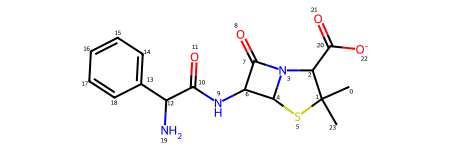

In [5]:
# Get a sample drug's SMILES and ID from the DataFrame
sample_drug_id = smiles_df.iloc[0]['drug_id']
sample_smiles = smiles_df.iloc[0]['smiles']

print(f"Sample Drug ID: {sample_drug_id}")
print(f"Sample SMILES: {sample_smiles}")

# Visualisation is optional -- never let a display problem stop the run.
try:
    from rdkit.Chem.Draw import IPythonConsole
    IPythonConsole.drawOptions.addAtomIndices = True
    mol = Chem.MolFromSmiles(sample_smiles)
    print("RDKit Molecule Visualization (with atom indices):")
    display(mol)
except Exception as e:
    print('(skipped molecule drawing:', type(e).__name__, ')')


In [6]:
# Convert the SMILES string to a graph representation using the defined function
graph_representation = smiles_to_graph(sample_smiles)

print("\nGraph Representation (torch_geometric.data.Data object):")
print(graph_representation)
print(f"Node features shape (x): {graph_representation.x.shape}")
print(f"Edge index shape: {graph_representation.edge_index.shape}")
print(f"Edge attributes shape: {graph_representation.edge_attr.shape}")


Graph Representation (torch_geometric.data.Data object):
Data(x=[24, 37], edge_index=[2, 52], edge_attr=[52, 7])
Node features shape (x): torch.Size([24, 37])
Edge index shape: torch.Size([2, 52])
Edge attributes shape: torch.Size([52, 7])


## Cell 5 — Side-effect profile: DIVERSE target term selection (fixes label collapse)

**New fix:** the previous version picked BOTH input and target terms by raw frequency. A diagnostic confirmed this let the 50-label side-effect task collapse to only ~62 distinct true answer patterns across the test set -- the near-perfect 0.99 score wasn't a shortcut, the task itself just wasn't as hard as the label count suggested. Target terms are now chosen via greedy min-max-correlation selection over a pool of reasonably common terms, so the 50 chosen targets are mutually diverse instead of naturally co-occurring together. Input terms are unaffected -- they're conditioning information, not the prediction target, so frequency-based selection is still appropriate there.

In [7]:
# Optional side-effect INPUT features only. No side-effect prediction head or targets are used.
# These features are used only by ablation variants with use_sider=True.
merged_path = os.path.join(DRIVE_OUTPUT_DIR, 'merged_side_effect_terms.csv')
terms_by_cid = {}
if os.path.exists(merged_path):
    merged_df = pd.read_csv(merged_path)
    terms_by_cid = merged_df.groupby('cid')['term'].apply(set).to_dict()
else:
    meddra_path = os.path.join(DRIVE_DATA_DIR, 'meddra_all_se.tsv')
    if os.path.exists(meddra_path):
        sider = pd.read_csv(meddra_path, sep='\t', header=None,
                            names=['cid_flat', 'cid_stereo', 'umls1', 'meddra_type', 'umls2', 'side_effect'])
        pt = sider[sider['meddra_type'] == 'PT'][['cid_stereo', 'side_effect']].drop_duplicates()
        terms_by_cid = pt.groupby('cid_stereo')['side_effect'].apply(
            lambda s: set(str(x).strip().lower() for x in s)).to_dict()

from collections import Counter
term_freq = Counter()
for cid, terms in terms_by_cid.items():
    if cid in graph_cache:
        term_freq.update(terms)
SIDER_INPUT_K = 50
input_side_effects = pd.Series(term_freq).nlargest(SIDER_INPUT_K).index.tolist()
input_se_to_idx = {term: i for i, term in enumerate(input_side_effects)}
sider_input_profiles = {}
for cid, terms in terms_by_cid.items():
    if cid not in graph_cache:
        continue
    vec = np.zeros(SIDER_INPUT_K, dtype=np.float32)
    for term in terms:
        if term in input_se_to_idx:
            vec[input_se_to_idx[term]] = 1.0
    sider_input_profiles[cid] = vec
zero_input = np.zeros(SIDER_INPUT_K, dtype=np.float32)
def get_sider_input_vec(drug_id):
    return sider_input_profiles.get(drug_id, zero_input)
print(f'Side-effect INPUT features available for {len(sider_input_profiles)} drugs; no side-effect prediction targets/head.')


Side-effect INPUT features available for 380 drugs; no side-effect prediction targets/head.


## Build the PAIR-LEVEL dataset (multi-label interaction types + risk)

**Changed:** `interaction_target` is now a multi-hot vector over the top-40 interaction types — 1 for every type recorded for that pair, 0 otherwise — instead of a single `mode()`-collapsed class. No `OTHER` class: a pair with none of the top-40 types just gets an all-zero vector, exactly like `OTHER` meant before, but without swallowing pairs that *do* have real top-40 types alongside long-tail ones.

In [8]:
ddi = pd.read_csv(os.path.join(DRIVE_DATA_DIR, 'ddis.csv'))
ddi = ddi[ddi['d1'].isin(graph_cache) & ddi['d2'].isin(graph_cache)].reset_index(drop=True)
print('Rows after filtering to parseable drugs:', len(ddi))

TOP_K = 40
type_counts_raw = ddi['type'].value_counts()
top_types = type_counts_raw.nlargest(TOP_K).index.tolist()
type_to_idx = {t: i for i, t in enumerate(top_types)}
NUM_INTERACTION_TYPES = len(top_types)
print('Multi-label interaction-type vocabulary size:', NUM_INTERACTION_TYPES)

sorted_types = type_counts_raw.sort_values(ascending=True)
n = len(sorted_types)
severe_types = set(sorted_types.index[: n // 3])
moderate_types = set(sorted_types.index[n // 3 : 2 * n // 3])

def type_risk(t):
    if t in severe_types: return 2
    if t in moderate_types: return 1
    return 0

ddi['type_risk'] = ddi['type'].apply(type_risk)

grouped = ddi.groupby(['d1', 'd2'])
records = []
n_zero_vector = 0
for (d1, d2), g in grouped:
    types_present = set(g['type'].unique())
    multihot = np.zeros(NUM_INTERACTION_TYPES, dtype=np.float32)
    for t in types_present:
        if t in type_to_idx:
            multihot[type_to_idx[t]] = 1.0
    if multihot.sum() == 0:
        n_zero_vector += 1
    mean_risk_score = g['type_risk'].mean()
    records.append({'d1': d1, 'd2': d2, 'interaction_target': multihot, 'mean_risk_score': mean_risk_score})

pair_df = pd.DataFrame(records)

# FIX (leakage): risk_label is NOT binned here anymore. Binning now happens after the
# split, using bin edges fit on the TRAIN fold only, so val/test never influence where
# the tercile boundaries fall. 'mean_risk_score' is carried through unbinned instead.

print('Unique pairs:', len(pair_df))
print('Pairs with NO top-40 type (all-zero interaction target):', n_zero_vector,
      f'({100 * n_zero_vector / len(pair_df):.1f}%)')
avg_types_per_pair = np.mean([v.sum() for v in pair_df['interaction_target']])
print(f'Average number of top-40 types present per pair: {avg_types_per_pair:.1f} / {NUM_INTERACTION_TYPES}')

Rows after filtering to parseable drugs: 4576287
Multi-label interaction-type vocabulary size: 40
Unique pairs: 63472
Pairs with NO top-40 type (all-zero interaction target): 681 (1.1%)
Average number of top-40 types present per pair: 12.9 / 40


In [9]:
print("Columns in pair_df:")
print(pair_df.columns.tolist())

print("\nSample rows:")
display(pair_df.head(10))

Columns in pair_df:
['d1', 'd2', 'interaction_target', 'mean_risk_score']

Sample rows:


,d1,d2,interaction_target,mean_risk_score
0,CID000000085,CID000000206,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.000000
1,CID000000085,CID000000271,"[1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.200000
2,CID000000085,CID000000444,"[0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 0.0, ...",0.195652
3,CID000000085,CID000000772,"[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.076923
4,CID000000085,CID000000853,"[1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, ...",0.270270
5,CID000000085,CID000000937,"[1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.285714
6,CID000000085,CID000000942,"[0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, ...",0.151515
7,CID000000085,CID000001983,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.200000
8,CID000000085,CID000002162,"[1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.228571
9,CID000000085,CID000002244,"[1.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...",0.250000


## Cell 7 — Add true negative (non-interacting) pairs from the raw `Neg samples` column

**New:** everything above only ever includes pairs that already have at least one recorded interaction row in `ddis.csv` — the model has never seen a pair that doesn't interact at all. `ddis.csv` ships its own `Neg samples` column for this: for each `(d1, d2, type)` row it gives a substitute drug guaranteed not to share *that specific* type with `d1`. That substitute pair can still be positive for a *different* type though (true for ~46% of raw candidates), so it isn't usable as-is — it has to be filtered down to pairs that are genuinely never positive for anything. This cell does that filtering directly from the raw file: no external preprocessing, no separate script, just `ddis.csv` as downloaded.

Negative pairs get an all-zero interaction target (no top-40 type applies) and `risk_label = 0` (no interaction = no risk, folded into the existing "Low" tercile).

In [10]:

# ============================================================
# CELL 7 — UNIFORM NEGATIVE SAMPLING BASELINE
# ============================================================

from collections import Counter
import numpy as np
import pandas as pd

# Flag read by later cells (cache signature). False = uniform negatives, which is what this cell does.
DEGREE_MATCHED_NEGATIVES = False

# 1. Recover positive-only pairs safely.
# This also prevents duplicate negatives if the cell is rerun.
positive_df = pair_df[
    pair_df['mean_risk_score'].notna()
].copy()

positive_df = positive_df.drop_duplicates(
    subset=['d1', 'd2']
).reset_index(drop=True)

print("Positive pairs:", len(positive_df))

# 2. Build canonical positive-pair keys.
# Both (A, B) and (B, A) represent the same pair.
all_positive_pairs = {
    (a, b) if a < b else (b, a)
    for a, b in zip(ddi['d1'], ddi['d2'])
    if a != b
}

# 3. Generate candidate pairs from the original Neg samples column.
neg_candidates = (
    ddi[['d1', 'Neg samples']]
    .dropna()
    .drop_duplicates()
    .rename(columns={'Neg samples': 'd2'})
)

neg_candidates = neg_candidates[
    neg_candidates['d1'].isin(graph_cache)
    & neg_candidates['d2'].isin(graph_cache)
    & (neg_candidates['d1'] != neg_candidates['d2'])
].copy()

neg_candidates['pair'] = [
    (a, b) if a < b else (b, a)
    for a, b in zip(neg_candidates['d1'], neg_candidates['d2'])
]

neg_candidates = neg_candidates.drop_duplicates(
    subset='pair'
)

# 4. Exclude pairs with any recorded positive interaction.
true_negatives = neg_candidates[
    ~neg_candidates['pair'].isin(all_positive_pairs)
].copy()

print("Genuine negative candidates:", len(true_negatives))

# 5. Uniform random sampling: one negative per positive.
NEG_RATIO = 1.0

n_negatives = min(
    len(true_negatives),
    int(len(positive_df) * NEG_RATIO)
)

if n_negatives == 0:
    raise ValueError("No genuine negative candidates available.")

sampled_negatives = true_negatives.sample(
    n=n_negatives,
    random_state=SEED
).copy()

# 6. Build negative records.
neg_df = pd.DataFrame({
    'd1': sampled_negatives['d1'].values,
    'd2': sampled_negatives['d2'].values,
    'interaction_target': [
        np.zeros(NUM_INTERACTION_TYPES, dtype=np.float32)
        for _ in range(n_negatives)
    ],
    'mean_risk_score': np.nan
})

# 7. Combine positive and negative pairs.
pair_df = pd.concat(
    [
        positive_df[
            ['d1', 'd2', 'interaction_target', 'mean_risk_score']
        ],
        neg_df
    ],
    ignore_index=True
)

# Final canonical-pair uniqueness check.
pair_df['_pair_key'] = [
    (a, b) if a < b else (b, a)
    for a, b in zip(pair_df['d1'], pair_df['d2'])
]

if pair_df['_pair_key'].duplicated().any():
    raise ValueError("Duplicate canonical pairs detected.")

pair_df = (
    pair_df.drop(columns='_pair_key')
    .sample(frac=1.0, random_state=SEED)
    .reset_index(drop=True)
)

n_positive_final = pair_df['mean_risk_score'].notna().sum()
n_negative_final = pair_df['mean_risk_score'].isna().sum()

print("\nUNIFORM SAMPLING RESULTS")
print("Positive pairs:", n_positive_final)
print("Negative pairs:", n_negative_final)
print("Total pairs:", len(pair_df))
print(
    "Negative/positive ratio:",
    round(n_negative_final / max(n_positive_final, 1), 3)
)


Positive pairs: 63472
Genuine negative candidates: 127986

UNIFORM SAMPLING RESULTS
Positive pairs: 63472
Negative pairs: 63472
Total pairs: 126944
Negative/positive ratio: 1.0


In [11]:

from collections import Counter
import pandas as pd

# Positive degrees
pos_deg = Counter()
for a, b in zip(positive_df['d1'], positive_df['d2']):
    pos_deg[a] += 1
    pos_deg[b] += 1

# Available genuine-negative candidate degrees
candidate_deg = Counter()
for a, b in zip(true_negatives['d1'], true_negatives['d2']):
    candidate_deg[a] += 1
    candidate_deg[b] += 1

degree_check = pd.DataFrame({
    'positive_degree': pd.Series(pos_deg),
    'negative_candidate_degree': pd.Series(candidate_deg)
}).fillna(0)

degree_check['candidate_to_positive_ratio'] = (
    degree_check['negative_candidate_degree']
    / degree_check['positive_degree'].clip(lower=1)
)

print(degree_check.describe().round(3))

print("\nDrugs with highest positive degrees:")
print(
    degree_check.sort_values('positive_degree', ascending=False)
    .head(15)
    .round(3)
)

print("\nDrugs with fewer negative candidates than positive partners:")
print(
    (degree_check['negative_candidate_degree']
     < degree_check['positive_degree']).sum()
)


       positive_degree  negative_candidate_degree  candidate_to_positive_ratio
count          645.000                    645.000                      645.000
mean           196.812                    396.856                       11.829
std            149.541                    118.384                       42.227
min              1.000                     45.000                        0.075
25%             69.000                    331.000                        1.111
50%            167.000                    426.000                        2.618
75%            300.000                    480.000                        7.382
max            599.000                    598.000                      464.000

Drugs with highest positive degrees:
              positive_degree  negative_candidate_degree  \
CID000004594              599                         45   
CID000001983              578                         66   
CID000000853              576                         68   
CID00000388

In [12]:
degree_check['degree_deficit'] = (
    degree_check['positive_degree']
    - degree_check['negative_candidate_degree']
).clip(lower=0)

print("Total positive degree:", degree_check['positive_degree'].sum())
print("Total candidate degree:", degree_check['negative_candidate_degree'].sum())
print("Total degree deficit:", degree_check['degree_deficit'].sum())

print("\nLargest candidate deficits:")
print(
    degree_check.sort_values('degree_deficit', ascending=False)
    [['positive_degree', 'negative_candidate_degree', 'degree_deficit']]
    .head(15)
)

Total positive degree: 126944
Total candidate degree: 255972
Total degree deficit: 30077

Largest candidate deficits:
              positive_degree  negative_candidate_degree  degree_deficit
CID000004594              599                         45             554
CID000001983              578                         66             512
CID000000853              576                         68             508
CID000003883              552                         92             460
CID000005039              549                         95             454
CID000003958              544                        100             444
CID000054454              537                        107             430
CID000004679              537                        107             430
CID000005732              537                        107             430
CID000002771              536                        108             428
CID000006691              535                        109             426
CID000

In [13]:

# Compare positive and final negative degrees per drug

from collections import Counter
import pandas as pd

positive_df = pair_df[
    pair_df['mean_risk_score'].notna()
]

negative_df = pair_df[
    pair_df['mean_risk_score'].isna()
]

def partner_degrees(df):
    counts = Counter()
    for a, b in zip(df['d1'], df['d2']):
        counts[a] += 1
        counts[b] += 1
    return counts

pos_deg_final = partner_degrees(positive_df)
neg_deg_final = partner_degrees(negative_df)

comparison = pd.DataFrame({
    'positive_degree': pd.Series(pos_deg_final),
    'negative_degree': pd.Series(neg_deg_final)
}).fillna(0)

comparison['degree_difference'] = (
    comparison['negative_degree'] -
    comparison['positive_degree']
)

print(
    "Spearman correlation:",
    round(
        comparison['positive_degree'].corr(
            comparison['negative_degree'],
            method='spearman'
        ),
        3
    )
)

print("\nDegree summary:")
print(comparison.describe().round(2))

print("\nLargest absolute differences:")
print(
    comparison.assign(
        abs_difference=comparison['degree_difference'].abs()
    ).sort_values(
        'abs_difference', ascending=False
    ).head(15)
)


Spearman correlation: -0.798

Degree summary:
       positive_degree  negative_degree  degree_difference
count           645.00           645.00             645.00
mean            196.81           196.81               0.00
std             149.54            59.99             204.57
min               1.00            14.00            -585.00
25%              69.00           164.00            -130.00
50%             167.00           208.00              50.00
75%             300.00           240.00             173.00
max             599.00           314.00             257.00

Largest absolute differences:
              positive_degree  negative_degree  degree_difference  \
CID000004594              599               14               -585   
CID000001983              578               25               -553   
CID000000853              576               42               -534   
CID000005039              549               45               -504   
CID000003883              552               53 

In [14]:

# Inspect negative-candidate availability for the highest-degree drugs

check_drugs = (
    degree_check
    .sort_values('positive_degree', ascending=False)
    .head(10)
    .index
)

for drug in check_drugs:
    candidates = true_negatives[
        (true_negatives['d1'] == drug) |
        (true_negatives['d2'] == drug)
    ]

    print(
        drug,
        "| positive degree:", int(pos_deg[drug]),
        "| genuine negative candidates:", len(candidates)
    )


CID000004594 | positive degree: 599 | genuine negative candidates: 45
CID000001983 | positive degree: 578 | genuine negative candidates: 66
CID000000853 | positive degree: 576 | genuine negative candidates: 68
CID000003883 | positive degree: 552 | genuine negative candidates: 92
CID000005039 | positive degree: 549 | genuine negative candidates: 95
CID000003958 | positive degree: 544 | genuine negative candidates: 100
CID000005732 | positive degree: 537 | genuine negative candidates: 107
CID000054454 | positive degree: 537 | genuine negative candidates: 107
CID000004679 | positive degree: 537 | genuine negative candidates: 107
CID000002771 | positive degree: 536 | genuine negative candidates: 108


In [15]:

# Compare original negative-sample coverage with filtered genuine negatives

top_drugs = degree_check.sort_values(
    'positive_degree', ascending=False
).head(10).index

raw_candidates = (
    ddi[['d1', 'Neg samples']]
    .dropna()
    .drop_duplicates()
    .rename(columns={'Neg samples': 'd2'})
)

raw_candidates = raw_candidates[
    raw_candidates['d1'] != raw_candidates['d2']
].copy()

raw_candidates['pair'] = [
    (a, b) if a < b else (b, a)
    for a, b in zip(raw_candidates['d1'], raw_candidates['d2'])
]

raw_candidates = raw_candidates.drop_duplicates('pair')

raw_genuine = raw_candidates[
    ~raw_candidates['pair'].isin(all_positive_pairs)
]

for drug in top_drugs:
    raw_count = raw_genuine[
        (raw_genuine['d1'] == drug) |
        (raw_genuine['d2'] == drug)
    ].shape[0]

    filtered_count = true_negatives[
        (true_negatives['d1'] == drug) |
        (true_negatives['d2'] == drug)
    ].shape[0]

    print(
        f"{drug}: original candidates={raw_count}, "
        f"filtered candidates={filtered_count}"
    )


CID000004594: original candidates=45, filtered candidates=45
CID000001983: original candidates=66, filtered candidates=66
CID000000853: original candidates=68, filtered candidates=68
CID000003883: original candidates=92, filtered candidates=92
CID000005039: original candidates=95, filtered candidates=95
CID000003958: original candidates=100, filtered candidates=100
CID000005732: original candidates=107, filtered candidates=107
CID000054454: original candidates=107, filtered candidates=107
CID000004679: original candidates=107, filtered candidates=107
CID000002771: original candidates=108, filtered candidates=108


## Cell 8 — Drug-disjoint ("cold") split, re-seedable

Drugs are split first, so a drug's graph only ever appears on one side. Pairs that straddle two drug groups are dropped (they cannot be kept without leaking). `COLD_VAL_FRAC` / `COLD_TEST_FRAC` are fractions of **drugs**, so pair counts shrink roughly with the square of those fractions. `make_cold_dfs(seed)` is reused by the ablation cell to build a fresh cold partition per seed.


In [16]:
print("Total pairs:", len(pair_df))
print(
    "Pairs with missing risk score:",
    int(pair_df['mean_risk_score'].isna().sum())
)
print(
    "Pairs with a risk score:",
    int(pair_df['mean_risk_score'].notna().sum())
)

Total pairs: 126944
Pairs with missing risk score: 63472
Pairs with a risk score: 63472


In [17]:
COLD_VAL_FRAC, COLD_TEST_FRAC = 0.15, 0.20   # fractions of DRUGS held out (train = the rest)

def make_cold_dfs(seed):
    """Drug-disjoint train/val/test DataFrames for a given partition seed.
    Risk-tercile bin edges are fit on TRAIN only (no val/test influence)."""
    drugs = pd.unique(pair_df[['d1', 'd2']].values.ravel())
    hold = COLD_VAL_FRAC + COLD_TEST_FRAC
    tr_d, tmp_d = train_test_split(drugs, test_size=hold, random_state=seed)
    va_d, te_d = train_test_split(tmp_d, test_size=COLD_TEST_FRAC / hold, random_state=seed)
    both = lambda ds: pair_df['d1'].isin(set(ds)) & pair_df['d2'].isin(set(ds))
    split = np.select([both(tr_d), both(va_d), both(te_d)], ['train', 'val', 'test'], default='drop')
    df = pair_df.assign(split=split)

    train_pos = df.loc[
        (df['split'] == 'train')
        & df['mean_risk_score'].notna(),
        'mean_risk_score'
    ]

    # Learn risk-bin boundaries from training data only
    _, raw_edges = pd.qcut(
        train_pos,
        q=3,
        retbins=True,
        duplicates='drop'
    )

    # Extend the outer boundaries to cover all validation/test scores
    edges = raw_edges.copy()
    edges[0] = -np.inf
    edges[-1] = np.inf

    n_bins = len(edges) - 1
    risk_labels = list(range(1, n_bins + 1))

    def bin_risk(d):
        d = d.copy()
        m = d['mean_risk_score'].notna()

        # 0 = no risk score; positive bins = scored pairs
        d['risk_label'] = 0

        if m.any():
            d.loc[m, 'risk_label'] = pd.cut(
                d.loc[m, 'mean_risk_score'],
                bins=edges,
                labels=risk_labels,
                include_lowest=True
            ).astype(int)

        return d.drop(columns=['mean_risk_score', 'split'])

    return tuple(bin_risk(df[df['split'] == n]).reset_index(drop=True) for n in ('train', 'val', 'test'))

train_df, val_df, test_df = make_cold_dfs(SEED)
n_drop = int((pair_df.shape[0] - len(train_df) - len(val_df) - len(test_df)))
print(f'Cold split (seed {SEED}): train/val/test pairs = {len(train_df)} / {len(val_df)} / {len(test_df)}  '
      f'({n_drop} straddling pairs dropped)')
# NOTE: risk_label is only used downstream to derive the gate target for the cold split (risk_label > 0 == real interacting pair).
print('Positive rate  train/val/test:', [round(float((d['risk_label'] > 0).mean()), 3) for d in (train_df, val_df, test_df)])

Cold split (seed 42): train/val/test pairs = 53423 / 2676 / 5354  (65491 straddling pairs dropped)
Positive rate  train/val/test: [0.501, 0.423, 0.54]


In [18]:

# Validate cold-start split integrity
# Uses risk_label because mean_risk_score is removed by make_cold_dfs()

train_df, val_df, test_df = make_cold_dfs(SEED)

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

drug_sets = {
    name: set(df["d1"]) | set(df["d2"])
    for name, df in splits.items()
}

print("=== COLD-START SPLIT VALIDATION ===")

for name, df in splits.items():
    # risk_label 0 = negative pair; labels 1, 2, 3 = positive pair
    positive = (df["risk_label"] > 0).sum()
    negative = (df["risk_label"] == 0).sum()

    print(
        f"{name}: pairs={len(df):,}, "
        f"positive={positive:,}, negative={negative:,}"
    )

print("\n=== DRUG OVERLAP CHECK ===")

print("Train vs validation:",
      len(drug_sets["train"] & drug_sets["validation"]))

print("Train vs test:",
      len(drug_sets["train"] & drug_sets["test"]))

print("Validation vs test:",
      len(drug_sets["validation"] & drug_sets["test"]))

print("\n=== TARGET CHECK ===")

for name, df in splits.items():
    print(
        name,
        "| missing risk labels:", df["risk_label"].isna().sum(),
        "| unique risk labels:",
        sorted(df["risk_label"].unique().tolist())
    )


=== COLD-START SPLIT VALIDATION ===
train: pairs=53,423, positive=26,790, negative=26,633
validation: pairs=2,676, positive=1,131, negative=1,545
test: pairs=5,354, positive=2,892, negative=2,462

=== DRUG OVERLAP CHECK ===
Train vs validation: 0
Train vs test: 0
Validation vs test: 0

=== TARGET CHECK ===
train | missing risk labels: 0 | unique risk labels: [0, 1, 2, 3]
validation | missing risk labels: 0 | unique risk labels: [0, 1, 2, 3]
test | missing risk labels: 0 | unique risk labels: [0, 1, 2, 3]


In [19]:

# Verify gate-target consistency against the original pair_df

train_df, val_df, test_df = make_cold_dfs(SEED)

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

print("=== GATE TARGET CONSISTENCY ===")

for name, df in splits.items():
    # Recover the original pairs using canonical pair keys
    original = pair_df.copy()

    original["_pair_key"] = [
        tuple(sorted((a, b)))
        for a, b in zip(original["d1"], original["d2"])
    ]

    split_keys = {
        tuple(sorted((a, b)))
        for a, b in zip(df["d1"], df["d2"])
    }

    original_part = original[
        original["_pair_key"].isin(split_keys)
    ].drop_duplicates("_pair_key")

    split_part = df.copy()
    split_part["_pair_key"] = [
        tuple(sorted((a, b)))
        for a, b in zip(split_part["d1"], split_part["d2"])
    ]

    original_part = original_part.set_index("_pair_key")
    split_part = split_part.set_index("_pair_key")

    expected = original_part["mean_risk_score"].notna().astype(int)
    actual = (split_part["risk_label"] > 0).astype(int)

    common = expected.index.intersection(actual.index)
    mismatches = (expected.loc[common] != actual.loc[common]).sum()

    print(f"{name}: mismatches={mismatches:,} / {len(common):,}")


=== GATE TARGET CONSISTENCY ===
train: mismatches=0 / 53,423
validation: mismatches=0 / 2,676
test: mismatches=0 / 5,354


In [20]:
train_drugs = set(train_df['d1']) | set(train_df['d2'])
val_drugs   = set(val_df['d1']) | set(val_df['d2'])
test_drugs  = set(test_df['d1']) | set(test_df['d2'])

print("Train/validation overlap:", len(train_drugs & val_drugs))
print("Train/test overlap:", len(train_drugs & test_drugs))
print("Validation/test overlap:", len(val_drugs & test_drugs))

assert len(train_drugs & val_drugs) == 0
assert len(train_drugs & test_drugs) == 0
assert len(val_drugs & test_drugs) == 0

print("PASS: all three drug sets are disjoint.")

Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0
PASS: all three drug sets are disjoint.


In [21]:
print("Columns in pair_df:")
print(pair_df.columns.tolist())

print("\nSample rows:")
display(pair_df.head(10))

Columns in pair_df:
['d1', 'd2', 'interaction_target', 'mean_risk_score']

Sample rows:


,d1,d2,interaction_target,mean_risk_score
0,CID000003249,CID000003690,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",NaN
1,CID000004513,CID000005512,"[0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...",0.179487
2,CID000002269,CID000003767,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.412500
3,CID000004674,CID000004046,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",NaN
4,CID000003827,CID000004473,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",NaN
5,CID000003410,CID000163742,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",NaN
6,CID000003032,CID000003345,"[0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.578231
7,CID000001983,CID000004107,"[1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, ...",0.383838
8,CID000002130,CID000004723,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",NaN
9,CID000005672,CID000148211,"[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, ...",0.171429


In [22]:

import numpy as np
import pandas as pd

# Convert interaction_target vectors into a 2D NumPy array
targets = np.stack(
    pair_df['interaction_target'].apply(np.asarray).to_numpy()
)

# True if a pair has at least one interaction type
has_interaction = (targets > 0).any(axis=1)

# Current risk-score-based label
has_risk_score = pair_df['mean_risk_score'].notna()

# Compare both definitions
comparison = pd.crosstab(
    pd.Series(has_interaction, name='Has interaction target'),
    pd.Series(has_risk_score, name='Has risk score'),
    margins=True
)

print("Interaction-target shape:", targets.shape)
print("\nGate-label comparison:")
display(comparison)

print("\nPairs with an interaction target:", int(has_interaction.sum()))
print("Pairs with no interaction target:", int((~has_interaction).sum()))
print("Pairs with a risk score:", int(has_risk_score.sum()))
print("Pairs without a risk score:", int((~has_risk_score).sum()))

# Identify disagreements
mismatch = has_interaction != has_risk_score

print("\nDisagreements between definitions:", int(mismatch.sum()))

if mismatch.any():
    display(
        pair_df.loc[
            mismatch,
            ['d1', 'd2', 'interaction_target', 'mean_risk_score']
        ].head(10)
    )


Interaction-target shape: (126944, 40)

Gate-label comparison:


Has risk score,False,True,All
Has interaction target,,,
False,63472,681,64153
True,0,62791,62791
All,63472,63472,126944



Pairs with an interaction target: 62791
Pairs with no interaction target: 64153
Pairs with a risk score: 63472
Pairs without a risk score: 63472

Disagreements between definitions: 681


,d1,d2,interaction_target,mean_risk_score
615,CID000003749,CID004659568,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.333333
720,CID000004112,CID005281007,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",1.000000
785,CID000003348,CID000004506,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.250000
863,CID000003345,CID000060754,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.333333
1270,CID000005735,CID000072054,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.200000
1604,CID000001978,CID000003367,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.250000
1638,CID000001046,CID000004138,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.000000
1718,CID000005538,CID000060831,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.000000
1788,CID000002541,CID000072054,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.000000
1797,CID000008953,CID000213039,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.333333


In [23]:

targets = np.stack(
    pair_df['interaction_target'].apply(np.asarray).to_numpy()
)

has_type = (targets > 0).any(axis=1)
has_score = pair_df['mean_risk_score'].notna().to_numpy()

# Pairs with a risk score but no positive target type
mask = has_score & ~has_type

print("Pairs with risk score but no selected type:", int(mask.sum()))
print("Unique target-vector sums:", np.unique(targets[mask].sum(axis=1)))
print(
    "Risk-score range for these pairs:",
    pair_df.loc[mask, 'mean_risk_score'].min(),
    pair_df.loc[mask, 'mean_risk_score'].max()
)

print("\nRisk-score examples:")
display(
    pair_df.loc[mask, ['d1', 'd2', 'mean_risk_score']].head(15)
)


Pairs with risk score but no selected type: 681
Unique target-vector sums: [0.]
Risk-score range for these pairs: 0.0 2.0

Risk-score examples:


,d1,d2,mean_risk_score
615,CID000003749,CID004659568,0.333333
720,CID000004112,CID005281007,1.000000
785,CID000003348,CID000004506,0.250000
863,CID000003345,CID000060754,0.333333
1270,CID000005735,CID000072054,0.200000
1604,CID000001978,CID000003367,0.250000
1638,CID000001046,CID000004138,0.000000
1718,CID000005538,CID000060831,0.000000
1788,CID000002541,CID000072054,0.000000
1797,CID000008953,CID000213039,0.333333


In [24]:

# Inspect available target arrays and their dimensions
print("Selected target shape:", targets.shape)

for name in ["Y", "Y_all", "Y_full", "D_Y", "full_targets"]:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: type={type(value).__name__}, "
            f"shape={getattr(value, 'shape', 'unknown')}"
        )


Selected target shape: (126944, 40)


In [25]:

print("=== Variables related to interaction targets ===")

for name, obj in list(globals().items()):
    if name.startswith("__"):
        continue

    name_lower = name.lower()
    relevant_name = any(
        word in name_lower
        for word in [
            "target", "interaction", "twoside",
            "decagon", "label", "effect", "ddi"
        ]
    )

    try:
        shape = getattr(obj, "shape", None)
        is_shape = isinstance(shape, tuple)
    except Exception:
        shape = None
        is_shape = False

    has_963_dimension = (
        is_shape and 963 in shape
    )

    if relevant_name or has_963_dimension:
        if is_shape:
            print(f"{name}: shape={shape}")
        elif isinstance(obj, (list, tuple)):
            print(
                f"{name}: type={type(obj).__name__}, "
                f"length={len(obj)}"
            )
        elif relevant_name:
            print(f"{name}: type={type(obj).__name__}")


=== Variables related to interaction targets ===
input_side_effects: type=list, length=50
ddi: shape=(4576287, 5)
type_counts_raw: shape=(963,)
NUM_INTERACTION_TYPES: type=int
sorted_types: shape=(963,)
targets: shape=(126944, 40)
has_interaction: shape=(126944,)


In [26]:

print("Original DDI columns:")
print(ddi.columns.tolist())

print("\nOriginal DDI shape:")
print(ddi.shape)

print("\nFirst 10 rows:")
display(ddi.head(10))

print("\nData types:")
print(ddi.dtypes)


Original DDI columns:
['d1', 'd2', 'type', 'Neg samples', 'type_risk']

Original DDI shape:
(4576287, 5)

First 10 rows:


,d1,d2,type,Neg samples,type_risk
0,CID000002173,CID000003345,0,CID000004885,0
1,CID000002173,CID000003345,1,CID000004425,0
2,CID000002173,CID000003345,2,CID000002617,0
3,CID000002173,CID000003345,3,CID000003066,0
4,CID000002173,CID000003345,4,CID000054841,0
5,CID000002173,CID000003345,5,CID005311181,0
6,CID000002173,CID000003345,6,CID000024011,1
7,CID000002173,CID000003345,7,CID000003108,1
8,CID000002173,CID000003345,8,CID000000159,0
9,CID000002173,CID000003345,9,CID000071329,0



Data types:
d1             object
d2             object
type            int64
Neg samples    object
type_risk       int64
dtype: object


In [27]:

# Identify pairs with a risk score but no positive target among the 40 types
targets = np.stack(
    pair_df['interaction_target'].apply(np.asarray).to_numpy()
)

has_type_40 = (targets > 0).any(axis=1)
has_risk = pair_df['mean_risk_score'].notna().to_numpy()
mismatch_mask = has_risk & ~has_type_40

mismatch_pairs = pair_df.loc[
    mismatch_mask, ['d1', 'd2']
].copy()

print("Pairs to investigate:", len(mismatch_pairs))

# Canonicalize pair order to make matching independent of d1/d2 order
mismatch_pairs['pair_key'] = mismatch_pairs.apply(
    lambda r: tuple(sorted((r['d1'], r['d2']))),
    axis=1
)

ddi_check = ddi.copy()

ddi_check['pair_key'] = [
    tuple(sorted((a, b)))
    for a, b in zip(ddi_check['d1'], ddi_check['d2'])
]

# Check whether each pair has any record in the original DDI table
original_pairs = set(ddi_check['pair_key'])
mismatch_keys = set(mismatch_pairs['pair_key'])

found_keys = mismatch_keys & original_pairs

print("Pairs found in original DDI table:", len(found_keys))
print("Pairs not found in original DDI table:", len(mismatch_keys - original_pairs))

# Inspect records for a few matching pairs
sample_keys = list(found_keys)[:5]

sample_records = ddi_check[
    ddi_check['pair_key'].isin(sample_keys)
][['d1', 'd2', 'type', 'Neg samples', 'type_risk']]

print("\nOriginal records for sample mismatched pairs:")
display(sample_records.head(30))


Pairs to investigate: 681
Pairs found in original DDI table: 681
Pairs not found in original DDI table: 0

Original records for sample mismatched pairs:


,d1,d2,type,Neg samples,type_risk
592212,CID000003640,CID000041693,614,CID000027686,1
592213,CID000003640,CID000041693,905,CID000003911,2
592214,CID000003640,CID000041693,278,CID000002250,0
592215,CID000003640,CID000041693,657,CID000003562,1
592216,CID000003640,CID000041693,95,CID000004932,0
592217,CID000003640,CID000041693,214,CID000002375,0
592218,CID000003640,CID000041693,548,CID000003736,0
592219,CID000003640,CID000041693,552,CID000002818,0
592220,CID000003640,CID000041693,391,CID000003463,0
592221,CID000003640,CID000041693,578,CID000002266,0


In [28]:

# Reuse mismatch_pairs and ddi_check from the previous cell

# Identify all original records for the 681 mismatched pairs
mismatch_records = ddi_check[
    ddi_check['pair_key'].isin(mismatch_keys)
].copy()

print("Total original records for mismatched pairs:",
      len(mismatch_records))

print("\nType-risk distribution:")
display(
    mismatch_records['type_risk']
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("record_count")
)

print("\nUnique interaction types per mismatched pair:")
type_counts = (
    mismatch_records.groupby('pair_key')['type']
    .nunique()
)

print(type_counts.describe())

print("\nExample pair: original type and risk records")
example_key = next(iter(mismatch_keys))

display(
    mismatch_records.loc[
        mismatch_records['pair_key'] == example_key,
        ['d1', 'd2', 'type', 'type_risk', 'Neg samples']
    ].sort_values('type')
)


Total original records for mismatched pairs: 4473

Type-risk distribution:


,record_count
type_risk,
0,2957
1,1074
2,442



Unique interaction types per mismatched pair:
count    681.000000
mean       6.568282
std        8.463857
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       93.000000
Name: type, dtype: float64

Example pair: original type and risk records


,d1,d2,type,type_risk,Neg samples
2088262,CID000003899,CID000163742,15,0,CID000005453
2088263,CID000003899,CID000163742,56,0,CID000003394
2088264,CID000003899,CID000163742,300,1,CID000003902


In [29]:

# Selected 40 interaction-type IDs
selected_type_ids = set(map(int, sorted_types))

# Records for the 681 mismatched pairs
records = ddi_check[
    ddi_check['pair_key'].isin(mismatch_keys)
].copy()

# Check whether each pair has any selected type in the original table
records['is_selected_type'] = records['type'].isin(selected_type_ids)

pair_summary = records.groupby('pair_key').agg(
    original_type_count=('type', 'nunique'),
    selected_type_count=('is_selected_type', 'sum'),
    risk_category_count=('type_risk', 'nunique')
)

print("Pairs with at least one selected type record:",
      int((pair_summary['selected_type_count'] > 0).sum()))

print("Pairs with no selected type record:",
      int((pair_summary['selected_type_count'] == 0).sum()))

print("\nSelected type record counts:")
display(pair_summary['selected_type_count'].value_counts().sort_index())

print("\nExample original records:")
display(
    records[
        ['d1', 'd2', 'type', 'type_risk', 'Neg samples']
    ].head(20)
)


Pairs with at least one selected type record: 223
Pairs with no selected type record: 458

Selected type record counts:


,count
selected_type_count,
0,458
1,152
2,41
3,13
4,7
5,3
6,2
8,2
11,1



Example original records:


,d1,d2,type,type_risk,Neg samples
3982,CID000039765,CID000041774,13,0,CID000004034
3983,CID000039765,CID000041774,368,0,CID000002802
3984,CID000039765,CID000041774,21,0,CID000004046
13269,CID000004253,CID000004497,79,0,CID000004748
13270,CID000004253,CID000004497,285,0,CID000039860
13271,CID000004253,CID000004497,749,1,CID000002274
13272,CID000004253,CID000004497,136,0,CID000087177
14198,CID000001302,CID000002800,69,0,CID000004264
14199,CID000001302,CID000002800,591,0,CID000004173
14200,CID000001302,CID000002800,420,0,CID000005038


In [30]:

# Select one pair from the 223 pairs with selected-type records
example_key = next(
    key for key in mismatch_keys
    if key in set(
        pair_summary.index[
            pair_summary['selected_type_count'] > 0
        ]
    )
)

# Find the pair's target vector
example_pair = pair_df[
    pair_df.apply(
        lambda r: tuple(sorted((r['d1'], r['d2']))) == example_key,
        axis=1
    )
]

print("Example pair:", example_key)
print("Pair target vector:")
display(example_pair[['d1', 'd2', 'mean_risk_score', 'interaction_target']])

print("\nSelected types recorded in ddi:")
display(
    ddi_check[
        ddi_check['pair_key'] == example_key
    ][['type', 'type_risk', 'Neg samples']]
    .sort_values('type')
)


Example pair: ('CID000003108', 'CID000003911')
Pair target vector:


,d1,d2,mean_risk_score,interaction_target
116543,CID000003108,CID000003911,1.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."



Selected types recorded in ddi:


,type,type_risk,Neg samples
2838283,67,0,CID000004542
2838281,745,1,CID000004845
2838282,914,2,CID000123620


In [31]:

example_types = set(
    ddi_check.loc[
        ddi_check['pair_key'] == example_key, 'type'
    ].astype(int)
)

selected_type_ids = set(map(int, sorted_types))

print("Original types for example pair:", sorted(example_types))
print("Selected 40 type IDs:", sorted(selected_type_ids))
print(
    "Overlap between original and selected types:",
    sorted(example_types & selected_type_ids)
)

# Inspect the target vector's positive positions
target_vec = np.asarray(
    example_pair.iloc[0]['interaction_target'],
    dtype=float
)

print("\nPositive target-vector positions (0-based):",
      np.flatnonzero(target_vec > 0).tolist())
print("Target vector length:", len(target_vec))


Original types for example pair: [67, 745, 914]
Selected 40 type IDs: [502, 504, 507, 508, 509, 510, 514, 515, 516, 519, 526, 527, 530, 533, 540, 546, 548, 551, 553, 555, 556, 557, 563, 565, 568, 572, 574, 583, 584, 589, 593, 598, 600, 602, 603, 608, 612, 617, 620, 624, 633, 634, 636, 644, 646, 649, 650, 651, 653, 654, 656, 657, 659, 661, 663, 665, 667, 670, 675, 676, 681, 685, 687, 689, 694, 696, 700, 709, 712, 714, 715, 720, 722, 725, 729, 733, 735, 736, 739, 744, 745, 746, 747, 750, 751, 755, 756, 760, 765, 766, 769, 775, 776, 783, 788, 790, 791, 792, 796, 799, 801, 803, 810, 814, 816, 821, 826, 827, 832, 833, 840, 842, 847, 848, 853, 857, 858, 862, 865, 870, 879, 882, 890, 898, 901, 912, 913, 917, 918, 921, 923, 925, 930, 931, 932, 935, 937, 941, 960, 961, 963, 966, 968, 970, 972, 978, 981, 987, 989, 991, 992, 997, 1001, 1006, 1012, 1013, 1016, 1020, 1021, 1023, 1024, 1025, 1030, 1034, 1042, 1056, 1060, 1066, 1072, 1076, 1084, 1085, 1089, 1093, 1097, 1105, 1109, 1110, 1119, 1123, 1

In [32]:

print("=== Selected-type mapping variables ===")

for name, obj in list(globals().items()):
    if name.startswith("__"):
        continue

    low = name.lower()

    if any(term in low for term in [
        "type_to", "type2", "type_idx", "type2idx",
        "idx_to_type", "type_map", "selected_types",
        "top_types", "type_to_idx", "type2id"
    ]):
        try:
            shape = getattr(obj, "shape", None)
        except Exception:
            shape = None

        print(
            name,
            "| type:", type(obj).__name__,
            "| shape:", shape
        )

print("\n=== sorted_types checks ===")
print("Length:", len(sorted_types))
print("First 20:", sorted_types[:20])
print("Last 20:", sorted_types[-20:])

print("\n=== Target construction clues ===")
print("interaction_target example length:",
      len(pair_df.iloc[66817]["interaction_target"]))
print("Target vector positive count:",
      int(np.sum(pair_df.iloc[66817]["interaction_target"])))


=== Selected-type mapping variables ===
top_types | type: list | shape: None
type_to_idx | type: dict | shape: None

=== sorted_types checks ===
Length: 963
First 20: type
951    502
936    504
29     507
533    507
945    508
868    509
763    510
779    510
555    514
830    515
904    516
943    516
962    516
724    519
932    526
853    526
910    527
888    530
762    530
901    533
Name: count, dtype: int64
Last 20: type
219    19376
77     19803
1      19930
116    20204
173    21013
53     21322
172    21410
227    21781
320    21806
297    21981
201    23043
200    23515
124    23848
98     23894
121    24260
62     24430
348    25190
24     26037
68     27006
45     28568
Name: count, dtype: int64

=== Target construction clues ===
interaction_target example length: 40
Target vector positive count: 0


In [33]:

# Use the actual 40-type vocabulary, not sorted_types
selected_type_ids = set(map(int, top_types))

print("Selected vocabulary size:", len(selected_type_ids))
print("Mapping size:", len(type_to_idx))
assert len(selected_type_ids) == 40
assert len(type_to_idx) == 40

# Check each of the 681 mismatched pairs against the real top-40 IDs
records = ddi_check[
    ddi_check['pair_key'].isin(mismatch_keys)
].copy()

records['is_top40'] = records['type'].isin(selected_type_ids)

top40_counts = records.groupby('pair_key')['is_top40'].sum()

print("\nMismatched pairs:", len(mismatch_keys))
print("Pairs with any top-40 type in ddi:",
      int((top40_counts > 0).sum()))
print("Pairs with no top-40 type in ddi:",
      int((top40_counts == 0).sum()))

print("\nTop-40 record count per pair:")
display(top40_counts.value_counts().sort_index())

# Check that the vector-building mapping agrees with top_types
mapping_consistent = all(
    type_to_idx[t] == i for i, t in enumerate(top_types)
)
print("\nMapping agrees with top_types order:", mapping_consistent)


Selected vocabulary size: 40
Mapping size: 40

Mismatched pairs: 681
Pairs with any top-40 type in ddi: 0
Pairs with no top-40 type in ddi: 681

Top-40 record count per pair:


,count
is_top40,
0,681



Mapping agrees with top_types order: True


## Cell 9 — Drug encoder (GATv2, shared across both drugs)

Keeps only `DrugEncoder` and `make_head`; the `PairNet` model in the v17 section below replaces the old 4-head model.


In [34]:
class DrugEncoder(nn.Module):
    def __init__(self, node_feat_dim, edge_feat_dim, hidden_dim=64, out_dim=128, heads=4, dropout=0.2):
        super().__init__()
        self.conv1 = GATv2Conv(node_feat_dim, hidden_dim, heads=heads, dropout=dropout, edge_dim=edge_feat_dim)
        self.conv2 = GATv2Conv(hidden_dim * heads, hidden_dim, heads=heads, dropout=dropout, edge_dim=edge_feat_dim)
        self.conv3 = GATv2Conv(hidden_dim * heads, out_dim, heads=1, concat=False, dropout=dropout, edge_dim=edge_feat_dim)

    def forward(self, x, edge_index, edge_attr, batch):
        x = F.elu(self.conv1(x, edge_index, edge_attr))
        x = F.elu(self.conv2(x, edge_index, edge_attr))
        x = self.conv3(x, edge_index, edge_attr)
        return global_mean_pool(x, batch)

def make_head(in_dim, out_dim, hidden=128, dropout=0.3):
    return nn.Sequential(
        nn.Linear(in_dim, hidden),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(hidden, out_dim),
    )


## v17 -- rebuilt evaluation + faster symmetric model (run AFTER the encoder cell)

**What changed and why**
- **Warm split (new primary test):** random new *pairs* between drugs the model has seen -- what your app does at runtime. Pairs are canonicalised (A|B == B|A) before splitting so a pair can't leak across splits. The drug-disjoint split stays available as `cold`.
- **Shortcut baseline:** per-drug interaction rate / type profile, no chemistry. A model has to beat this to claim it learned anything about *pairs*.
- **Metrics:** AUROC / AP (threshold-free), types scored both over all pairs and *within interacting pairs only*; F1 only at the end with thresholds tuned on validation.
- **Model:** exactly symmetric pair encoder; GNN encodes all drugs once per step (much faster); optional Morgan-fingerprint branch and learned drug-ID embedding; 4-variant ablation so we see which ingredient actually helps.
- **Dropped from this experiment:** the risk head (its labels measure how rare a type is, not severity) and the pair-level side-effect head (it is a per-drug property).


In [35]:
import random, copy, time
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

_required = ['pair_df', 'graph_cache', 'smiles_df', 'get_sider_input_vec', 'DrugEncoder', 'NODE_FEAT_DIM',
             'EDGE_FEAT_DIM', 'SIDER_INPUT_K', 'NUM_INTERACTION_TYPES', 'train_df', 'val_df', 'test_df',
             'device', 'SEED', 'DRIVE_OUTPUT_DIR', 'Batch', 'make_cold_dfs']
_missing = [r for r in _required if r not in globals()]
assert not _missing, ('Run all earlier cells (through the DrugEncoder cell) first. '
                      f'Missing: {_missing}')

T = NUM_INTERACTION_TYPES


# ---------------------------------------------------------------- metrics
def _safe_auc_ap(Y, S):
    """Mean per-column AUROC / AP; columns with one class in Y are skipped."""
    aucs, aps = [], []
    for j in range(Y.shape[1]):
        if Y[:, j].min() == Y[:, j].max():
            continue
        aucs.append(roc_auc_score(Y[:, j], S[:, j]))
        aps.append(average_precision_score(Y[:, j], S[:, j]))
    return (float(np.mean(aucs)), float(np.mean(aps))) if aucs else (float('nan'), float('nan'))


def metrics_v17(Y, G, p_types, p_gate, p_within=None):
    """Y: (N,T) multi-hot, G: (N,) 1 = pair interacts at all.
    p_within: scores used for 'interacting only' type ranking (defaults to p_types)."""
    if p_within is None:
        p_within = p_types
    pos = G > 0
    m = {}
    m['gate AUROC'] = float(roc_auc_score(G, p_gate))
    m['gate AP'] = float(average_precision_score(G, p_gate))
    m['types macro-AUROC (all pairs)'], m['types macro-AP (all pairs)'] = _safe_auc_ap(Y, p_types)
    m['types macro-AUROC (interacting only)'], m['types macro-AP (interacting only)'] = _safe_auc_ap(Y[pos], p_within[pos])
    return m


def f1_report(val, test):
    """val/test = (Y, G, p_types, p_gate). Thresholds are tuned on VAL only, then applied to TEST.
    Reference points: predicting everything positive."""
    Yv, Gv, ptv, pgv = val
    Yt, Gt, ptt, pgt = test
    grid = np.arange(0.05, 0.96, 0.01)
    tg = grid[int(np.argmax([f1_score(Gv, pgv > t, zero_division=0) for t in grid]))]
    gate_v, gate_t = pgv > tg, pgt > tg
    tgrid = np.arange(0.05, 0.96, 0.05)
    thr = np.array([max(tgrid, key=lambda t: f1_score(Yv[:, j], (ptv[:, j] > t) & gate_v, zero_division=0))
                    for j in range(Yv.shape[1])])
    pred = (ptt > thr[None, :]) & gate_t[:, None]
    return {
        'gate threshold (val-tuned)': float(tg),
        'gate F1': float(f1_score(Gt, gate_t, zero_division=0)),
        'gate F1 if always "interacts"': float(f1_score(Gt, np.ones_like(Gt), zero_division=0)),
        'types micro-F1 (gate + tuned thr)': float(f1_score(Yt, pred, average='micro', zero_division=0)),
        'types micro-F1 if all types positive': float(f1_score(Yt, np.ones_like(Yt), average='micro', zero_division=0)),
        '_type_thresholds': thr,
    }


# ---------------------------------------------------------------- drug index + splits
def _canon(a, b):
    a, b = str(a), str(b)
    return f'{a}|{b}' if a < b else f'{b}|{a}'


drug_ids = sorted(set(pair_df['d1']) | set(pair_df['d2']), key=str)
d2i = {d: i for i, d in enumerate(drug_ids)}
N_DRUGS = len(drug_ids)


def pack(d1, d2, Y, G):
    return dict(i1=np.array([d2i[x] for x in d1]), i2=np.array([d2i[x] for x in d2]),
                Y=np.asarray(Y, dtype=np.float32), G=np.asarray(G, dtype=np.float32))


def build_cold_split(seed):
    """Fresh drug-disjoint split for this partition seed (both drugs unseen at test time); hardest case."""
    tr_, va_, te_ = make_cold_dfs(seed)
    return {n: pack(d['d1'], d['d2'], np.stack(d['interaction_target'].values), (d['risk_label'] > 0).values)
            for n, d in [('train', tr_), ('val', va_), ('test', te_)]}


# --- WARM split: random NEW PAIRS between drugs the model has seen (what the app does at runtime).
# Pairs are canonicalised (A|B == B|A) BEFORE splitting so the same pair can never sit in train
# in one order and in test in the other. The gate target is "is a real interacting pair" (taken from
# mean_risk_score being non-null), which also fixes the ~1% of positives whose types fall outside top-40.
P = pair_df.copy()
P['ck'] = [_canon(a, b) for a, b in zip(P['d1'], P['d2'])]
P['is_pos'] = P['mean_risk_score'].notna()
n_dup = int(P.duplicated('ck', keep=False).sum())
print(f'pair_df rows: {len(P)} | rows sharing a canonical pair key with another row: {n_dup}')

Yall = np.stack(P['interaction_target'].values).astype(np.float32)
_tmp = pd.DataFrame(Yall)
_tmp['is_pos'] = P['is_pos'].values.astype(np.int8)
_tmp['ck'] = P['ck'].values
agg = _tmp.groupby('ck', sort=False).max()
first = P.drop_duplicates('ck').set_index('ck').loc[agg.index]
w_d1, w_d2 = first['d1'].values, first['d2'].values
w_Y = agg[list(range(T))].values.astype(np.float32)
w_G = agg['is_pos'].values.astype(np.float32)

_idx = np.arange(len(w_G))
_tr, _tmp_i = train_test_split(_idx, test_size=0.2, stratify=w_G, random_state=SEED)
_va, _te = train_test_split(_tmp_i, test_size=0.5, stratify=w_G[_tmp_i], random_state=SEED)
SPLITS = {
    'warm': {n: pack(w_d1[ix], w_d2[ix], w_Y[ix], w_G[ix]) for n, ix in [('train', _tr), ('val', _va), ('test', _te)]},
    'cold': build_cold_split(SEED),   # rebuilt per seed by activate_split() in the ablation cell
}
for sp, parts in SPLITS.items():
    print(sp, {k: f"{len(v['G'])} pairs, {100 * v['G'].mean():.1f}% interacting" for k, v in parts.items()})


# ---------------------------------------------------------------- shortcut baselines (no chemistry at all)
def drug_profile_baseline(tr, ev, a=5.0):
    """Scores a pair only from how often each of its two drugs interacted / which types it had in TRAIN.
    If a neural model cannot beat this, it has only learned drug identity, not pair-level chemistry."""
    Yt, Gt, i1t, i2t = tr['Y'], tr['G'], tr['i1'], tr['i2']
    g, gprof = Gt.mean(), Yt[Gt > 0].mean(axis=0)
    cnt, pos = np.zeros(N_DRUGS), np.zeros(N_DRUGS)
    pcnt, psum = np.zeros(N_DRUGS), np.zeros((N_DRUGS, Yt.shape[1]))
    m = Gt > 0
    for ii in (i1t, i2t):
        np.add.at(cnt, ii, 1)
        np.add.at(pos, ii, Gt)
        np.add.at(pcnt, ii[m], 1)
        np.add.at(psum, ii[m], Yt[m])
    rate = (pos + a * g) / (cnt + a)
    prof = (psum + a * gprof[None, :]) / (pcnt[:, None] + a)
    gate = (rate[ev['i1']] + rate[ev['i2']]) / 2
    within = (prof[ev['i1']] + prof[ev['i2']]) / 2
    return within * gate[:, None], gate, within


BASELINES = {}   # (split, seed) -> metrics.  Warm uses one fixed split (key seed 0); cold is re-partitioned per seed.


def activate_split(sp, seed):
    """Make SPLITS[sp] ready for this seed and make sure its no-chemistry baseline is computed."""
    if sp == 'cold':
        SPLITS['cold'] = build_cold_split(SEED + seed)
    key = (sp, seed if sp == 'cold' else 0)
    if key not in BASELINES:
        parts = SPLITS[sp]
        pt, pg, pw = drug_profile_baseline(parts['train'], parts['test'])
        BASELINES[key] = metrics_v17(parts['test']['Y'], parts['test']['G'], pt, pg, pw)
    return key


for _sp in SPLITS:
    activate_split(_sp, 0)
print('\n=== SHORTCUT BASELINE (per-drug interaction rate / type profile, no chemistry) — TEST ===')
print(pd.DataFrame({sp: BASELINES[(sp, 0)] for sp in SPLITS}).round(3).to_string())
print('\nRead this as the bar a real model must clear. A random scorer gets AUROC 0.5.')


pair_df rows: 126944 | rows sharing a canonical pair key with another row: 0
warm {'train': '101555 pairs, 50.0% interacting', 'val': '12694 pairs, 50.0% interacting', 'test': '12695 pairs, 50.0% interacting'}
cold {'train': '53423 pairs, 50.1% interacting', 'val': '2676 pairs, 42.3% interacting', 'test': '5354 pairs, 54.0% interacting'}

=== SHORTCUT BASELINE (per-drug interaction rate / type profile, no chemistry) — TEST ===
                                       warm   cold
gate AUROC                            0.931  0.500
gate AP                               0.939  0.540
types macro-AUROC (all pairs)         0.857  0.500
types macro-AP (all pairs)            0.553  0.167
types macro-AUROC (interacting only)  0.726  0.500
types macro-AP (interacting only)     0.557  0.310

Read this as the bar a real model must clear. A random scorer gets AUROC 0.5.


In [36]:
# ============================================================
# GLOBAL MOLECULAR DESCRIPTORS
# Structure-derived features for cold-start generalization
# ============================================================

from rdkit.Chem import Descriptors, Lipinski, Crippen, rdMolDescriptors

DESC_NAMES = [
    'MolWt',
    'LogP',
    'TPSA',
    'HBD',
    'HBA',
    'RotatableBonds',
    'RingCount',
    'AromaticRings',
    'FractionCSP3',
    'HeavyAtomCount',
    'AliphaticRings',
    'SaturatedRings'
]

def molecular_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return np.array([
        Descriptors.MolWt(mol),
        Crippen.MolLogP(mol),
        rdMolDescriptors.CalcTPSA(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol),
        Lipinski.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumRings(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        rdMolDescriptors.CalcFractionCSP3(mol),
        Descriptors.HeavyAtomCount(mol),
        rdMolDescriptors.CalcNumAliphaticRings(mol),
        rdMolDescriptors.CalcNumSaturatedRings(mol)
    ], dtype=np.float32)


# Build descriptor table in the SAME drug order used by D.batch / D.fp
_smi = dict(zip(smiles_df['drug_id'], smiles_df['smiles']))

desc_list = []
desc_fail = 0

for d in drug_ids:
    desc = molecular_descriptors(_smi[d])

    if desc is None or not np.all(np.isfinite(desc)):
        desc_fail += 1
        desc = np.zeros(len(DESC_NAMES), dtype=np.float32)

    desc_list.append(desc)

D_RAW_DESC = np.stack(desc_list).astype(np.float32)

print("Molecular descriptor table built")
print("Drugs:", D_RAW_DESC.shape[0])
print("Descriptor dimension:", D_RAW_DESC.shape[1])
print("Failed:", desc_fail)
print("Descriptors:", DESC_NAMES)

Molecular descriptor table built
Drugs: 645
Descriptor dimension: 12
Failed: 0
Descriptors: ['MolWt', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'AromaticRings', 'FractionCSP3', 'HeavyAtomCount', 'AliphaticRings', 'SaturatedRings']


## PairNet — the actual model being trained

Symmetric pair encoder: `f(A,B) == f(B,A)` exactly. Each of the four ablation configs below just switches which per-drug representations feed into it (GNN / fingerprint / learned drug-ID embedding / SIDER), so we can see which ingredient is actually earning its keep.

In [37]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


# ============================================================
# STATIC PER-DRUG INPUTS
# ============================================================

class DrugData:
    pass


D = DrugData()

# Molecular graphs
D.batch = Batch.from_data_list(
    [graph_cache[d] for d in drug_ids]
).to(device)

# SIDER
D.sider = torch.tensor(
    np.stack([
        get_sider_input_vec(d)
        for d in drug_ids
    ]),
    dtype=torch.float,
    device=device
)

# Morgan fingerprints
_smi = dict(zip(
    smiles_df['drug_id'],
    smiles_df['smiles']
))

_mfp = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

D.fp = torch.tensor(
    np.stack([
        _mfp.GetFingerprintAsNumPy(
            Chem.MolFromSmiles(_smi[d])
        ).astype(np.float32)
        for d in drug_ids
    ]),
    dtype=torch.float,
    device=device
)

# ============================================================
# MOLECULAR DESCRIPTORS
# ============================================================

D.desc = torch.tensor(
    D_RAW_DESC,
    dtype=torch.float,
    device=device
)

DESC_DIM = D.desc.shape[1]

print("Descriptor tensor:", D.desc.shape)

print(
    f"Drug table built: {N_DRUGS} drugs | "
    f"node feats {NODE_FEAT_DIM} | "
    f"edge feats {EDGE_FEAT_DIM} | "
    f"fp 2048 | "
    f"descriptors {DESC_DIM}"
)


# ============================================================
# PAIR NETWORK
# ============================================================

class PairNet(nn.Module):

    """
    Per-drug representation:

        GNN embedding
        Morgan fingerprint
        Molecular descriptors
        Learned drug-ID embedding
        SIDER input

    Each component is switchable for ablation.

    Pair representation:

        [r1+r2, r1*r2, |r1-r2|]

    This guarantees:

        f(A,B) == f(B,A)

    Outputs:

        - interaction type logits
        - interaction gate logit
    """

    def __init__(
        self,
        known_mask,
        use_gnn,
        use_fp,
        use_id,
        use_sider,
        use_desc,

        gnn_out=128,
        fp_out=128,
        desc_out=32,
        id_dim=64,

        hid=256,
        dropout=0.3,
        id_drop=0.2
    ):

        super().__init__()

        self.use_gnn = use_gnn
        self.use_fp = use_fp
        self.use_id = use_id
        self.use_sider = use_sider
        self.use_desc = use_desc

        self.id_drop = id_drop

        self.register_buffer(
            'known_mask',
            torch.tensor(
                known_mask,
                dtype=torch.float
            ).unsqueeze(1)
        )

        d = 0

        # ----------------------------------------------------
        # GNN branch
        # ----------------------------------------------------

        if use_gnn:

            self.encoder = DrugEncoder(
                NODE_FEAT_DIM,
                EDGE_FEAT_DIM,
                out_dim=gnn_out
            )

            d += gnn_out

        # ----------------------------------------------------
        # Morgan fingerprint branch
        # ----------------------------------------------------

        if use_fp:

            self.fp_mlp = nn.Sequential(
                nn.Linear(2048, 256),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(256, fp_out)
            )

            d += fp_out

        # ----------------------------------------------------
        # Molecular descriptor branch
        # ----------------------------------------------------

        if use_desc:

            self.desc_mlp = nn.Sequential(
                nn.Linear(DESC_DIM, 64),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(64, desc_out)
            )

            d += desc_out

        # ----------------------------------------------------
        # Drug ID branch
        # ----------------------------------------------------

        if use_id:

            self.id_emb = nn.Embedding(
                N_DRUGS,
                id_dim
            )

            d += id_dim

        # ----------------------------------------------------
        # SIDER branch
        # ----------------------------------------------------

        if use_sider:

            d += SIDER_INPUT_K

        # ----------------------------------------------------
        # Drug representation projection
        # ----------------------------------------------------

        self.proj = nn.Sequential(
            nn.Linear(d, hid),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # ----------------------------------------------------
        # Symmetric pair representation
        # ----------------------------------------------------

        self.trunk = nn.Sequential(
            nn.Linear(hid * 3, hid),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # ----------------------------------------------------
        # Prediction heads
        # ----------------------------------------------------

        self.head_types = nn.Linear(
            hid,
            T
        )

        self.head_gate = nn.Linear(
            hid,
            1
        )


    def drug_table(self, train_mode):

        parts = []

        # ----------------------------------------------------
        # GNN
        # ----------------------------------------------------

        if self.use_gnn:

            b = D.batch

            parts.append(
                self.encoder(
                    b.x,
                    b.edge_index,
                    b.edge_attr,
                    b.batch
                )
            )

        # ----------------------------------------------------
        # Morgan fingerprint
        # ----------------------------------------------------

        if self.use_fp:

            parts.append(
                self.fp_mlp(D.fp)
            )

        # ----------------------------------------------------
        # Molecular descriptors
        # ----------------------------------------------------

        if self.use_desc:

            parts.append(
                self.desc_mlp(D.desc)
            )

        # ----------------------------------------------------
        # Drug ID
        # ----------------------------------------------------

        if self.use_id:

            e = (
                self.id_emb.weight
                * self.known_mask
            )

            if train_mode and self.id_drop > 0:

                e = e * (
                    torch.rand(
                        e.size(0),
                        1,
                        device=e.device
                    ) > self.id_drop
                ).float()

            parts.append(e)

        # ----------------------------------------------------
        # SIDER
        # ----------------------------------------------------

        if self.use_sider:

            parts.append(
                D.sider
            )

        # ----------------------------------------------------
        # Final drug representation
        # ----------------------------------------------------

        return self.proj(
            torch.cat(
                parts,
                dim=1
            )
        )


    def forward(
        self,
        table,
        i1,
        i2
    ):

        r1 = table[i1]
        r2 = table[i2]

        h = self.trunk(
            torch.cat(
                [
                    r1 + r2,
                    r1 * r2,
                    (r1 - r2).abs()
                ],
                dim=1
            )
        )

        return (
            self.head_types(h),
            self.head_gate(h).squeeze(1)
        )


# ============================================================
# PREDICTION
# ============================================================

@torch.no_grad()
def predict(
    net,
    part,
    chunk=8192
):

    net.eval()

    table = net.drug_table(
        train_mode=False
    )

    i1 = torch.as_tensor(
        part['i1'],
        device=device
    )

    i2 = torch.as_tensor(
        part['i2'],
        device=device
    )

    pt = []
    pg = []

    for k in range(
        0,
        len(i1),
        chunk
    ):

        lt, lg = net(
            table,
            i1[k:k + chunk],
            i2[k:k + chunk]
        )

        pt.append(
            torch.sigmoid(
                lt
            ).cpu().numpy()
        )

        pg.append(
            torch.sigmoid(
                lg
            ).cpu().numpy()
        )

    return (
        np.concatenate(pt),
        np.concatenate(pg)
    )


# ============================================================
# TRAIN ONE SPLIT
# ============================================================

def run_one(
    split,
    cfg,
    seed,
    epochs=40,
    patience=6,
    bs=1024,
    lr=1e-3,
    wd=1e-4,
    verbose=False
):
    set_seed(seed)

    S = SPLITS[split]
    tr = S['train']

    # ========================================================
    # 1. Identify drugs that are actually seen during training
    # ========================================================

    known = np.zeros(N_DRUGS, dtype=bool)

    known[tr['i1']] = True
    known[tr['i2']] = True

    train_drug_idx = np.where(known)[0]

    # ========================================================
    # 2. Compute descriptor normalization statistics
    #    USING TRAINING DRUGS ONLY
    # ========================================================

    desc_train = D_RAW_DESC[train_drug_idx]

    desc_mean = desc_train.mean(axis=0)
    desc_std = desc_train.std(axis=0)

    # Prevent division by zero for any constant descriptor
    desc_std = np.where(
        desc_std < 1e-8,
        1.0,
        desc_std
    )

    # ========================================================
    # 3. Normalize ALL drugs using TRAINING statistics
    #
    # Important:
    # Validation/test drugs are NOT used to calculate mean/std.
    # Their descriptors are simply transformed using the
    # training statistics.
    # ========================================================

    desc_normalized = (
        D_RAW_DESC - desc_mean
    ) / desc_std

    # Replace any numerical problems
    desc_normalized = np.nan_to_num(
        desc_normalized,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    ).astype(np.float32)

    # ========================================================
    # 4. Temporarily replace D.desc with normalized descriptors
    # ========================================================

    D.desc = torch.tensor(
        desc_normalized,
        dtype=torch.float,
        device=device
    )

    # ========================================================
    # 5. Create model
    # ========================================================

    net = PairNet(
        known,
        **cfg
    ).to(device)

    opt = torch.optim.AdamW(
        net.parameters(),
        lr=lr,
        weight_decay=wd
    )

    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt,
        mode='max',
        factor=0.5,
        patience=2
    )

    # ========================================================
    # 6. Training tensors
    # ========================================================

    i1 = torch.as_tensor(
        tr['i1'],
        device=device
    )

    i2 = torch.as_tensor(
        tr['i2'],
        device=device
    )

    Y = torch.as_tensor(
        tr['Y'],
        device=device
    )

    G = torch.as_tensor(
        tr['G'],
        device=device
    )

    n = len(i1)

    # ========================================================
    # 7. Training state
    # ========================================================

    best_sel = -1.0
    best_state = None
    best_ep = 0
    bad = 0

    # ========================================================
    # 8. Training loop
    # ========================================================

    for ep in range(
        1,
        epochs + 1
    ):

        net.train()

        perm = torch.randperm(
            n,
            device=device
        )

        tot = 0.0

        for k in range(
            0,
            n,
            bs
        ):

            ix = perm[
                k:k + bs
            ]

            # Build drug representation table
            table = net.drug_table(
                train_mode=True
            )

            lt, lg = net(
                table,
                i1[ix],
                i2[ix]
            )

            # Type prediction loss
            type_loss = F.binary_cross_entropy_with_logits(
                lt,
                Y[ix]
            )

            # Interaction gate loss
            gate_loss = F.binary_cross_entropy_with_logits(
                lg,
                G[ix]
            )

            loss = type_loss + gate_loss

            opt.zero_grad()

            loss.backward()

            nn.utils.clip_grad_norm_(
                net.parameters(),
                5.0
            )

            opt.step()

            tot += (
                loss.item()
                * len(ix)
            )

        # ====================================================
        # 9. Validation
        # ====================================================

        pt, pg = predict(
            net,
            S['val']
        )

        mv = metrics_v17(
            S['val']['Y'],
            S['val']['G'],
            pt,
            pg
        )

        sel = (
            0.5 * mv['gate AUROC']
            +
            0.5 * mv[
                'types macro-AUROC (all pairs)'
            ]
        )

        sched.step(sel)

        if verbose:

            print(
                f'  ep {ep:02d} '
                f'loss {tot / n:.4f} | '
                f'val gate AUROC '
                f'{mv["gate AUROC"]:.3f} '
                f'types AUROC '
                f'{mv["types macro-AUROC (all pairs)"]:.3f} '
                f'| sel {sel:.4f}'
            )

        # ====================================================
        # 10. Save best model
        # ====================================================

        if sel > best_sel:

            best_sel = sel
            best_ep = ep
            bad = 0

            best_state = {
                k_: v.detach().clone()
                for k_, v in net.state_dict().items()
            }

        else:

            bad += 1

            if bad >= patience:
                break

    # ========================================================
    # 11. Restore best model
    # ========================================================

    net.load_state_dict(
        best_state
    )

    # ========================================================
    # 12. Validation and test predictions
    # ========================================================

    pv = predict(
        net,
        S['val']
    )

    pte = predict(
        net,
        S['test']
    )

    # ========================================================
    # 13. Test metrics
    # ========================================================

    res = metrics_v17(
        S['test']['Y'],
        S['test']['G'],
        pte[0],
        pte[1]
    )

    res['best epoch'] = best_ep
    res['val sel'] = best_sel

    # ========================================================
    # 14. F1 report
    # ========================================================

    f1 = f1_report(
        (
            S['val']['Y'],
            S['val']['G'],
            pv[0],
            pv[1]
        ),
        (
            S['test']['Y'],
            S['test']['G'],
            pte[0],
            pte[1]
        )
    )

    # ========================================================
    # 15. Return results
    # ========================================================

    return (
        res,
        f1,
        {
            k_: v.cpu()
            for k_, v in best_state.items()
        },
        known
    )

Descriptor tensor: torch.Size([645, 12])
Drug table built: 645 drugs | node feats 37 | edge feats 7 | fp 2048 | descriptors 12


## Training + diagnostics (v24)

One cell trains the structure-only model (GATv2 + Morgan fingerprint + RDKit descriptors, no drug-ID embedding, no SIDER input), then reports for it:

- warm-split test metrics against the no-chemistry baseline,
- train / val / test gap (overfit check),
- calibration (Brier, ECE, temperature scaling fitted on validation),
- bootstrap 95% CIs,
- a side-effect head on the frozen model (5 drug splits) against two kNN baselines,
- a cold check (both drugs unseen) over 3 partitions.

`QUICK_V23 = True` is a smoke test (30 warm / 25 cold epochs). Set it to `False` for the full run (150 / 60 epochs, early stopping applies). Risk output needs a type-name CSV (see the risk cell); everything else runs without it.


In [38]:
# ================= v22 -- RULE-BASED risk (derived from interaction types; no ML risk head) =================
# The interaction types in ddis.csv are numeric IDs, so severity rules need a mapping  type id -> name.
# Put a CSV somewhere on Drive with two columns (first = type id as in ddis.csv, second = type name) and set the path:
TYPE_NAMES_CSV = os.path.join(DRIVE_DATA_DIR, 'type_names_with_risk.csv')     # e.g. os.path.join(DRIVE_DATA_DIR, 'type_names.csv')
import re, pickle

SEV_NAMES = {-1: 'None', 0: 'Low', 1: 'Moderate', 2: 'High'}

# Keyword -> clinical severity tier, matched (case-insensitive, word-start) against each interaction-type name.
# Highest matching tier wins; unmatched types default to Low and are PRINTED below so you can review them.
HIGH_KW = ['haemorrhag', 'hemorrhag', 'bleed', 'renal failure', 'kidney failure', 'acute kidney', 'hepatic failure',
           'liver failure', 'cardiac arrest', 'cardiac failure', 'heart failure', 'myocardial infarction', 'stroke',
           'cerebrovascular', 'torsade', 'qt prolong', 'ventricular', 'arrhythm', 'serotonin syndrome',
           'rhabdomyolysis', 'anaphyla', 'angioedema', 'seizure', 'convulsion', 'respiratory depression',
           'respiratory failure', 'respiratory arrest', 'sepsis', 'septic', 'shock', 'coma', 'embol', 'thrombosis',
           'death', 'suicid', 'agranulocytosis', 'pancytopenia', 'stevens-johnson', 'toxic epidermal', 'overdose',
           'hyperkal']
MOD_KW = ['hypotension', 'hypertension', 'tachycardia', 'bradycardia', 'syncope', 'dizz', 'confusion', 'anaemia',
          'anemia', 'thrombocytopenia', 'leukopenia', 'neutropenia', 'dehydration', 'hypoglyc', 'hypokal',
          'hyponat', 'hypercalc', 'oedema', 'edema', 'vomit', 'diarrh', 'pneumonia', 'infection', 'pain',
          'fracture', 'renal', 'hepatic', 'liver', 'jaundice', 'dyspn', 'asthma', 'depress', 'anxiety',
          'hallucinat', 'somnolence', 'sedation', 'tremor', 'rash', 'urticaria', 'pruritus', 'fever', 'pyrexia',
          'insomnia', 'palpitation', 'chest', 'cough']

# Manual overrides after you review the printed table, e.g. {'some type name': 2}. 0=Low, 1=Moderate, 2=High.
SEV_OVERRIDE = {
    # High — heuristic assignments requiring clinical review
    'Difficulty breathing': 2,
    'Hypoventilation': 2,

    # Moderate — heuristic assignments requiring clinical review
    'arterial pressure NOS decreased': 1,
    'nausea': 1,
    'neumonia': 1,
    'Fatigue': 1,
    'asthenia': 1,
    'emesis': 1,
    'body temperature increased': 1,
    'Back Ache': 1,
    'Head ache': 1,
    'High blood pressure': 1,
    'hyperglycaemia': 1,
    'Anorexia': 1,
    'Aching joints': 1,
    'neuropathy': 1,
    'constipated': 1,
    'heart rate increased': 1,
    'Pleural Effusion': 1,
}


def _sev_of(name):
    n = str(name).lower()
    if name in SEV_OVERRIDE:
        return SEV_OVERRIDE[name], 'override'
    for tier, kws in ((2, HIGH_KW), (1, MOD_KW)):
        for kw in kws:
            if re.search(r'\b' + re.escape(kw), n):
                return tier, kw
    return 0, None



type_names = {t: str(t) for t in top_types}
RISK_AVAILABLE = bool(TYPE_NAMES_CSV) and os.path.exists(TYPE_NAMES_CSV)
if RISK_AVAILABLE:

    _m = pd.read_csv(TYPE_NAMES_CSV)

    # Explicitly use the correct CSV columns
    _map = {}
    for _, row in _m.iterrows():
        type_id = int(row['type_id'])
        type_name = str(row['type_name']).strip()

        _map[type_id] = type_name
        _map[str(type_id)] = type_name

    type_names = {
        t: str(_map.get(t, _map.get(str(t), t)))
        for t in top_types
    }

    n_missing = sum(1 for t in top_types if t not in _map and str(t) not in _map)
    print(f'Loaded type names from {TYPE_NAMES_CSV} | top-40 types without a name: {n_missing}')

    _sev = [_sev_of(type_names[t]) for t in top_types]
    SEV_VEC = np.array([s[0] for s in _sev], dtype=np.float32)
    print(f'Severity of the {len(top_types)} interaction types: '
          f'High={int((SEV_VEC == 2).sum())}, Moderate={int((SEV_VEC == 1).sum())}, Low={int((SEV_VEC == 0).sum())}')
    for tier in (2, 1, 0):
        print(f'\n--- {SEV_NAMES[tier]} ---')
        for t, (s, kw) in zip(top_types, _sev):
            if s == tier:
                print(f'   {type_names[t]}' + (f'   [matched: {kw}]' if kw else '   [no keyword matched -> default Low: REVIEW]'))
    print('\nReview the table above; put corrections in SEV_OVERRIDE (keyed by NAME) and re-run. '
          'These tiers are a documented heuristic, not clinical ground truth.')
else:
    SEV_VEC = None
    print('RISK SKIPPED: no type-name mapping (TYPE_NAMES_CSV is not set or the file is missing). '
          'Interaction types are numeric IDs, so keyword severity rules cannot be applied. '
          'Everything else in this notebook runs without it.')


# ---------------------------------------------------------------- rule: types -> risk tier
def sev_score(hit):
    """Mean severity (0..2) of the types that are present/predicted for each pair; 0 if none."""
    hit = np.asarray(hit, dtype=np.float32)
    n = hit.sum(axis=1)
    return np.where(n > 0, (hit * SEV_VEC[None, :]).sum(axis=1) / np.maximum(n, 1), 0.0)


def fit_risk_edges(Y_train, G_train):
    """Tier cut-points = 1/3 and 2/3 quantiles of the rule score over TRAIN interacting pairs only."""
    s = sev_score(Y_train[G_train > 0] > 0.5)
    return np.quantile(s, [1 / 3, 2 / 3])


def tier_from_score(score, edges):
    return (score > edges[0]).astype(int) + (score > edges[1]).astype(int)


def risk_tier(p_types, p_gate, type_thr, gate_thr, edges):
    """-1 = no interaction predicted, else 0/1/2 (Low/Moderate/High) from the predicted type set."""
    hit = p_types > np.asarray(type_thr)[None, :]
    tier = tier_from_score(sev_score(hit), edges)
    return np.where(p_gate > gate_thr, tier, -1)


def true_tier(Y, G, edges):
    tier = tier_from_score(sev_score(np.asarray(Y) > 0.5), edges)
    return np.where(np.asarray(G) > 0, tier, -1)

Loaded type names from /content/drive/MyDrive/Colab Notebooks/pro/datasets/type_names_with_risk.csv | top-40 types without a name: 0
Severity of the 40 interaction types: High=5, Moderate=33, Low=2

--- High ---
   Difficulty breathing   [matched: override]
   Hypoventilation   [matched: override]
   kidney failure   [matched: kidney failure]
   acute kidney failure   [matched: kidney failure]
   sepsis   [matched: sepsis]

--- Moderate ---
   arterial pressure NOS decreased   [matched: override]
   anaemia   [matched: anaemia]
   nausea   [matched: override]
   neumonia   [matched: override]
   Fatigue   [matched: override]
   Pain   [matched: pain]
   diarrhea   [matched: diarrh]
   asthenia   [matched: override]
   emesis   [matched: override]
   edema extremities   [matched: edema]
   body temperature increased   [matched: override]
   pleural pain   [matched: pain]
   abdominal pain   [matched: pain]
   chest pain   [matched: pain]
   dizziness   [matched: dizz]
   Back Ache   [ma

In [39]:
# ================= v24: STRUCTURE-ONLY EXPERIMENT (warm + cold) =================

import pickle
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    brier_score_loss
)

# ===========================================================
# CHECK REQUIRED OBJECTS FROM PREVIOUS CELLS
# ===========================================================

assert (
    'PairNet' in globals()
    and 'RISK_AVAILABLE' in globals()
), 'Run every earlier cell first.'

activate_split('warm', 0)

ALWAYS_KEY = 'gate F1 if always "interacts"'


def apply_desc_stats(mean, std):
    """Point D.desc at the descriptors normalised with the given (training-drug) mean/std."""
    z = (D_RAW_DESC - mean) / std
    D.desc = torch.tensor(np.nan_to_num(z, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32),
                          dtype=torch.float, device=device)

# ===========================================================
# MODEL
# ===========================================================

class PairNetV23(PairNet):

    """
    v23 PairNet with:

    1. Optional per-drug additive bias
       on type logits and gate logit.

    2. No side-effect prediction head.

    For V25 structure-only experiment:
        use_gnn   = True
        use_fp    = True
        use_id    = False
        use_sider = False
        use_bias  = False
    """

    def __init__(
        self,
        known_mask,
        n_actions=4,
        use_bias=False,
        bias_drop=0.2,
        action_hid=128,
        action_dropout=0.2,
        **cfg
    ):

        super().__init__(
            known_mask,
            **cfg
        )

        self.use_bias = use_bias
        self.bias_drop = bias_drop

        hid = self.head_types.in_features

        # Hierarchical clinical-action head: trunk representation + predicted
        # interaction-mechanism probabilities (T = NUM_INTERACTION_TYPES).
        self.head_action = nn.Sequential(
            nn.Linear(hid + T, action_hid),
            nn.ReLU(),
            nn.Dropout(action_dropout),
            nn.Linear(action_hid, n_actions)
        )

        if use_bias:

            self.type_bias = nn.Embedding(
                N_DRUGS,
                T
            )

            self.gate_bias = nn.Embedding(
                N_DRUGS,
                1
            )

            nn.init.zeros_(
                self.type_bias.weight
            )

            nn.init.zeros_(
                self.gate_bias.weight
            )


    def forward(self, table, i1, i2):

        r1 = table[i1]
        r2 = table[i2]

        h = self.trunk(
            torch.cat(
                [
                    r1 + r2,
                    r1 * r2,
                    (r1 - r2).abs()
                ],
                dim=1
            )
        )

        lt = self.head_types(h)
        lg = self.head_gate(h).squeeze(1)
        # Condition clinical-action prediction on both the pair representation
        # and predicted mechanism probabilities.
        type_probs = torch.sigmoid(lt)
        la = self.head_action(torch.cat([h, type_probs], dim=1))

        if self.use_bias:

            tb = (
                self.type_bias.weight
                * self.known_mask
            )

            gb = (
                self.gate_bias.weight
                * self.known_mask
            )

            if self.training and self.bias_drop > 0:

                keep = (
                    torch.rand(
                        tb.size(0),
                        1,
                        device=tb.device
                    )
                    > self.bias_drop
                ).float()

                tb = tb * keep
                gb = gb * keep

            lt = (
                lt
                + tb[i1]
                + tb[i2]
            )

            lg = (
                lg
                + (gb[i1] + gb[i2]).squeeze(1)
            )

        return lt, lg, la


    def _base_parts(self, train_mode):

        parts = []

        if self.use_gnn:
            b = D.batch
            parts.append(
                self.encoder(
                    b.x,
                    b.edge_index,
                    b.edge_attr,
                    b.batch
                )
            )

        if self.use_fp:
            parts.append(
                self.fp_mlp(D.fp)
            )

        if self.use_desc:
            parts.append(
                self.desc_mlp(D.desc)
            )

        if self.use_id:
            e = (
                self.id_emb.weight
                * self.known_mask
            )

            if train_mode and self.id_drop > 0:
                e = e * (
                    torch.rand(
                        e.size(0),
                        1,
                        device=e.device
                    ) > self.id_drop
                ).float()

            parts.append(e)

        return parts


# ===========================================================
# CLINICAL PRESCRIBING ACTION HEAD
# ===========================================================

ACTION_NAMES = [
    "Safe Concomitant Use (Standard Regimen)",
    "Time-Separated Administration (Spacing: 2-4 Hours)",
    "Dose Adjustment & Clinical Monitoring",
    "Strict Contraindication (Absolute Avoidance)",
]


def fit_clinical_action_probe(net, csv_path, epochs=30, batch_size=512, lr=1e-3):
    """Train only head_action on frozen pair-trunk embeddings concatenated with predicted mechanism probabilities."""
    if not os.path.exists(csv_path):
        raise FileNotFoundError(
            f"Missing clinical actions file: {csv_path}. Upload pair_clinical_actions.csv to DRIVE_OUTPUT_DIR."
        )
    df_act = pd.read_csv(csv_path)
    required = {"drug_a_cid", "drug_b_cid", "action_label"}
    missing = required - set(df_act.columns)
    if missing:
        raise ValueError(f"Clinical action CSV is missing columns: {sorted(missing)}")

    cid_to_i = {str(cid).strip(): idx for idx, cid in enumerate(drug_ids)}
    v1, v2, labels = [], [], []
    skipped = 0
    for row in df_act.itertuples(index=False):
        c1 = str(getattr(row, "drug_a_cid")).strip()
        c2 = str(getattr(row, "drug_b_cid")).strip()
        try:
            label = int(getattr(row, "action_label"))
        except (TypeError, ValueError):
            skipped += 1
            continue
        if c1 not in cid_to_i or c2 not in cid_to_i or label not in range(4):
            skipped += 1
            continue
        v1.append(cid_to_i[c1]); v2.append(cid_to_i[c2]); labels.append(label)

    if len(labels) < 5:
        raise ValueError(f"Only {len(labels)} valid labeled drug pairs mapped; need more rows to train/validate head_action.")
    idx1 = torch.tensor(v1, dtype=torch.long)
    idx2 = torch.tensor(v2, dtype=torch.long)
    y = torch.tensor(labels, dtype=torch.long)
    print(f"[head_action] Mapped {len(y):,} pairs; skipped {skipped:,} rows.")

    # Stratified split where possible; fallback to seeded random split for rare classes.
    from sklearn.model_selection import train_test_split
    ids = np.arange(len(y))
    try:
        tr_ids, va_ids = train_test_split(ids, test_size=0.2, random_state=42, stratify=np.asarray(labels))
    except ValueError:
        rng = np.random.default_rng(42); rng.shuffle(ids)
        cut = max(1, min(len(ids)-1, int(0.8 * len(ids))))
        tr_ids, va_ids = ids[:cut], ids[cut:]

    tr_t = torch.as_tensor(tr_ids, dtype=torch.long)
    va_t = torch.as_tensor(va_ids, dtype=torch.long)
    train_labels = y[tr_t]
    counts = torch.bincount(train_labels, minlength=4).float()
    # Avoid division by zero for a tier absent from the training split.
    weights = torch.zeros_like(counts)
    present = counts > 0
    weights[present] = len(train_labels) / (int(present.sum()) * counts[present])
    weights = weights.to(device)
    if not present.all():
        print(f"[head_action] Warning: absent training classes: {torch.where(~present)[0].tolist()}")

    net.eval()
    with torch.no_grad():
        table = net.drug_table(False)
        def make_h(rows):
            a = idx1[rows].to(device); b = idx2[rows].to(device)
            r1, r2 = table[a], table[b]
            pair = torch.cat([r1 + r2, r1 * r2, (r1 - r2).abs()], dim=1)
            h = net.trunk(pair)
            type_probs = torch.sigmoid(net.head_types(h))
            return torch.cat([h, type_probs], dim=1).detach()
        h_tr = make_h(tr_t)
        h_va = make_h(va_t)
        y_tr = train_labels.to(device)
        y_va = y[va_t].to(device)

    # Freeze everything except the clinical action head.
    for p in net.parameters(): p.requires_grad_(False)
    for p in net.head_action.parameters(): p.requires_grad_(True)
    for layer in net.head_action:
        if hasattr(layer, "reset_parameters"): layer.reset_parameters()

    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(net.head_action.parameters(), lr=lr, weight_decay=1e-4)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(h_tr, y_tr), batch_size=batch_size, shuffle=True
    )
    best_f1, best_state = -1.0, None
    for epoch in range(1, epochs + 1):
        net.head_action.train()
        for bh, by in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(net.head_action(bh), by)
            loss.backward(); optimizer.step()
        net.head_action.eval()
        with torch.no_grad():
            pred = net.head_action(h_va).argmax(dim=1).cpu().numpy()
        macro = f1_score(y_va.cpu().numpy(), pred, average="macro", zero_division=0)
        if macro > best_f1:
            best_f1 = macro
            best_state = {k: v.detach().cpu().clone() for k, v in net.head_action.state_dict().items()}
        if epoch % 5 == 0 or epoch == epochs:
            print(f"[head_action] Epoch {epoch:02d}/{epochs} | validation Macro-F1={macro:.4f} | best={best_f1:.4f}")
    if best_state is None:
        raise RuntimeError("Clinical action head training did not produce a valid checkpoint.")
    net.head_action.load_state_dict(best_state)
    for p in net.parameters(): p.requires_grad_(True)
    return {"val_macro_f1": float(best_f1), "class_counts": counts.cpu().tolist(), "n_pairs": int(len(y))}


# ===========================================================
# WARM SPLIT
# ===========================================================

def build_warm_split(ss):

    """
    ss = 0 uses exact v21 warm split.
    ss > 0 redraws random 80/10/10 pair split.
    """

    if ss == 0:

        return SPLITS['warm']

    tr_, tmp_ = train_test_split(
        _idx,
        test_size=0.2,
        stratify=w_G,
        random_state=SEED + ss
    )

    va_, te_ = train_test_split(
        tmp_,
        test_size=0.5,
        stratify=w_G[tmp_],
        random_state=SEED + ss
    )

    return {
        n: pack(
            w_d1[ix],
            w_d2[ix],
            w_Y[ix],
            w_G[ix]
        )
        for n, ix in [
            ('train', tr_),
            ('val', va_),
            ('test', te_)
        ]
    }


def split_baseline(S):

    pt, pg, pw = drug_profile_baseline(
        S['train'],
        S['test']
    )

    return metrics_v17(
        S['test']['Y'],
        S['test']['G'],
        pt,
        pg,
        p_within=pw
    )


@torch.no_grad()
def predict_v24(net, part, chunk=4096):
    net.eval()
    i1 = torch.as_tensor(part['i1'], dtype=torch.long, device=device)
    i2 = torch.as_tensor(part['i2'], dtype=torch.long, device=device)
    pt_all, pg_all = [], []
    table = net.drug_table(False)
    for k in range(0, len(i1), chunk):
        lt, lg, _ = net(table, i1[k:k+chunk], i2[k:k+chunk])
        pt_all.append(torch.sigmoid(lt).cpu().numpy())
        pg_all.append(torch.sigmoid(lg).cpu().numpy())
    return np.concatenate(pt_all), np.concatenate(pg_all)

# ===========================================================
# TRAINING
# ===========================================================

def train_pair(
    S,
    cfg,
    use_bias,
    seed,
    epochs,
    patience,
    bs=1024,
    lr=1e-3,
    wd=1e-4
):

    set_seed(seed)

    tr = S['train']

    known = np.zeros(
        N_DRUGS,
        dtype=bool
    )

    known[tr['i1']] = True
    known[tr['i2']] = True

    # ================================================
    # DESCRIPTOR NORMALIZATION — TRAINING DRUGS ONLY
    # ================================================

    # Always start with the original, unnormalized descriptors.
    desc_raw = D_RAW_DESC.copy()

    # Identify drugs appearing in training pairs only.
    train_drug_idx = np.where(known)[0]

    # Calculate normalization statistics using training drugs.
    desc_mean = desc_raw[train_drug_idx].mean(axis=0)
    desc_std = desc_raw[train_drug_idx].std(axis=0)

    # Avoid division by zero.
    desc_std = np.where(desc_std < 1e-8, 1.0, desc_std)

    # Apply the training statistics to every drug.
    desc_normalized = (desc_raw - desc_mean) / desc_std

    # Handle any unexpected numerical values.
    desc_normalized = np.nan_to_num(
        desc_normalized,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    ).astype(np.float32)

    # Supply normalized descriptors to the model.
    D.desc = torch.tensor(
        desc_normalized,
        dtype=torch.float,
        device=device
    )


    net = PairNetV23(
        known,
        n_actions=4,
        use_bias=use_bias,
        **cfg
    ).to(device)

    opt = torch.optim.AdamW(
        net.parameters(),
        lr=lr,
        weight_decay=wd
    )

    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt,
        mode='max',
        factor=0.5,
        patience=2
    )

    i1 = torch.as_tensor(
        tr['i1'],
        device=device
    )

    i2 = torch.as_tensor(
        tr['i2'],
        device=device
    )

    Y = torch.as_tensor(
        tr['Y'],
        device=device
    )

    G = torch.as_tensor(
        tr['G'],
        device=device
    )

    n = len(i1)

    best_sel = -1.0
    best_state = None
    best_ep = 0
    bad = 0

    for ep in range(
        1,
        epochs + 1
    ):

        net.train()

        perm = torch.randperm(
            n,
            device=device
        )

        for k in range(
            0,
            n,
            bs
        ):

            ix = perm[
                k:k + bs
            ]

            lt, lg, _ = net(
                net.drug_table(True),
                i1[ix],
                i2[ix]
            )

            loss = (
                F.binary_cross_entropy_with_logits(
                    lt,
                    Y[ix]
                )
                +
                F.binary_cross_entropy_with_logits(
                    lg,
                    G[ix]
                )
            )

            opt.zero_grad()

            loss.backward()

            nn.utils.clip_grad_norm_(
                net.parameters(),
                5.0
            )

            opt.step()

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        pt, pg = predict_v24(
            net,
            S['val']
        )

        mv = metrics_v17(
            S['val']['Y'],
            S['val']['G'],
            pt,
            pg
        )

        sel = (
            0.5
            * mv['gate AUROC']
            +
            0.5
            * mv[
                'types macro-AUROC (all pairs)'
            ]
        )

        sched.step(sel)

        if ep % 10 == 0:

            print(
                f'      ep {ep:3d} | '
                f'val gate '
                f'{mv["gate AUROC"]:.4f} '
                f'types '
                f'{mv["types macro-AUROC (all pairs)"]:.4f} '
                f'| sel {sel:.4f}'
            )

        sel_ok = bool(np.isfinite(sel))

        if best_state is None or (sel_ok and sel > best_sel):

            best_sel = sel if sel_ok else -1.0
            best_ep = ep
            bad = 0

            best_state = {
                k_: v.detach().clone()
                for k_, v
                in net.state_dict().items()
            }

        else:

            bad += 1

            if bad >= patience:
                break

    net.load_state_dict(
        best_state
    )

    return net, dict(
        best_ep=best_ep,
        sel=best_sel,
        known=known,
        epochs_run=ep,
        desc_mean=desc_mean,
        desc_std=desc_std
    )


# ============================================================
# DIAGNOSTICS
# ============================================================

def _types_auc(Y, Sc):

    a = [
        roc_auc_score(
            Y[:, j],
            Sc[:, j]
        )
        for j in range(
            Y.shape[1]
        )
        if Y[:, j].min()
        != Y[:, j].max()
    ]

    return float(
        np.mean(a)
    )


def _logit(p):

    p = np.clip(
        p,
        1e-6,
        1 - 1e-6
    )

    return np.log(
        p / (1 - p)
    )


def fit_temperature(
    p_val,
    g_val
):

    z = _logit(p_val)

    def nll(t):

        q = np.clip(
            1 / (
                1
                + np.exp(-z / t)
            ),
            1e-9,
            1 - 1e-9
        )

        return -np.mean(
            g_val * np.log(q)
            +
            (1 - g_val)
            * np.log(1 - q)
        )

    return float(
        minimize_scalar(
            nll,
            bounds=(0.05, 10.0),
            method='bounded'
        ).x
    )


def ece_score(
    p,
    g,
    bins=10
):

    edges = np.linspace(
        0,
        1,
        bins + 1
    )

    idx = np.clip(
        np.digitize(
            p,
            edges[1:-1]
        ),
        0,
        bins - 1
    )

    e = 0.0

    for b in range(bins):

        m = idx == b

        if m.any():

            e += (
                m.mean()
                *
                abs(
                    p[m].mean()
                    -
                    g[m].mean()
                )
            )

    return float(e)


def bootstrap_ci(
    Y,
    G,
    pt,
    pg,
    n_boot=100,
    seed=0
):

    rng = np.random.default_rng(seed)

    N = len(G)

    ga = []
    ta = []

    for _ in range(n_boot):

        ix = rng.integers(
            0,
            N,
            N
        )

        ga.append(
            roc_auc_score(
                G[ix],
                pg[ix]
            )
        )

        ta.append(
            _types_auc(
                Y[ix],
                pt[ix]
            )
        )

    q = lambda a: (
        float(np.percentile(a, 2.5)),
        float(np.percentile(a, 97.5))
    )

    return {
        'gate AUROC 95% CI': q(ga),
        'types AUROC 95% CI': q(ta)
    }


def diagnose(
    net,
    S,
    seed_tag
):

    rng = np.random.default_rng(123)

    tr = S['train']

    sub = rng.choice(
        len(tr['G']),
        size=min(
            15000,
            len(tr['G'])
        ),
        replace=False
    )

    trs = {
        k: v[sub]
        for k, v in tr.items()
    }

    out = {}

    for nm, part in [
        ('train', trs),
        ('val', S['val']),
        ('test', S['test'])
    ]:

        pt, pg = predict_v24(
            net,
            part
        )

        m = metrics_v17(
            part['Y'],
            part['G'],
            pt,
            pg
        )

        out[nm] = (
            m['gate AUROC'],
            m[
                'types macro-AUROC (all pairs)'
            ],
            m[
                'types macro-AUROC (interacting only)'
            ]
        )

    pv = predict_v24(
        net,
        S['val']
    )

    pte = predict_v24(
        net,
        S['test']
    )

    f1 = f1_report(
        (
            S['val']['Y'],
            S['val']['G'],
            pv[0],
            pv[1]
        ),
        (
            S['test']['Y'],
            S['test']['G'],
            pte[0],
            pte[1]
        )
    )

    T_ = fit_temperature(
        pv[1],
        S['val']['G']
    )

    p_cal = (
        1
        /
        (
            1
            +
            np.exp(
                -_logit(pte[1])
                / T_
            )
        )
    )

    g = S['test']['G']

    cal = {
        'T': T_,
        'Brier raw': brier_score_loss(
            g,
            pte[1]
        ),
        'Brier cal': brier_score_loss(
            g,
            p_cal
        ),
        'ECE raw': ece_score(
            pte[1],
            g
        ),
        'ECE cal': ece_score(
            p_cal,
            g
        )
    }

    return (
        out,
        f1,
        cal,
        pte,
        pv
    )


# ============================================================
# SIDE-EFFECT BASELINES
# ============================================================

FP_NP = D.fp.detach().cpu().numpy()


def knn_fp(
    tr_tbl,
    Ytr,
    te_tbl,
    k=5
):

    A = FP_NP[te_tbl]
    B = FP_NP[tr_tbl]

    inter = A @ B.T

    Sm = (
        inter
        /
        (
            A.sum(1)[:, None]
            +
            B.sum(1)[None, :]
            -
            inter
            +
            1e-9
        )
    )

    nn_idx = np.argsort(
        -Sm,
        axis=1
    )[:, :k]

    w = (
        np.take_along_axis(
            Sm,
            nn_idx,
            axis=1
        )
        + 1e-6
    )

    return (
        (
            Ytr[nn_idx]
            * w[:, :, None]
        ).sum(1)
        /
        w.sum(
            1,
            keepdims=True
        )
    )


def interaction_profile(tr):

    Yp = np.column_stack([
        tr['Y'],
        tr['G']
    ]).astype(
        np.float64
    )

    prof = np.zeros((
        N_DRUGS,
        Yp.shape[1]
    ))

    cnt = np.zeros(
        N_DRUGS
    )

    for ix in (
        tr['i1'],
        tr['i2']
    ):

        np.add.at(
            prof,
            ix,
            Yp
        )

        np.add.at(
            cnt,
            ix,
            1.0
        )

    prof /= np.maximum(
        cnt,
        1
    )[:, None]

    seen = cnt > 0

    mu = prof[seen].mean(
        0
    )

    sd = (
        prof[seen].std(
            0
        )
        + 1e-9
    )

    return np.where(
        seen[:, None],
        (prof - mu) / sd,
        0.0
    )


def knn_iprof(
    IP,
    tr_tbl,
    Ytr,
    te_tbl,
    k=5
):

    A = IP[te_tbl]
    B = IP[tr_tbl]

    A = (
        A
        /
        (
            np.linalg.norm(
                A,
                axis=1,
                keepdims=True
            )
            + 1e-9
        )
    )

    B = (
        B
        /
        (
            np.linalg.norm(
                B,
                axis=1,
                keepdims=True
            )
            + 1e-9
        )
    )

    Sm = A @ B.T

    nn_idx = np.argsort(
        -Sm,
        axis=1
    )[:, :k]

    w = (
        np.maximum(
            np.take_along_axis(
                Sm,
                nn_idx,
                axis=1
            ),
            0
        )
        + 1e-6
    )

    return (
        (
            Ytr[nn_idx]
            * w[:, :, None]
        ).sum(1)
        /
        w.sum(
            1,
            keepdims=True
        )
    )


# ============================================================
# RUN CONFIGURATION
# ============================================================

QUICK_V23 = False     # True = ~15 min smoke test, False = full run

RUN_B = False

RUN_COLD_CHECK = True

WARM_SPLIT_SEEDS = [0]

COLD_SEEDS = [0, 1, 2]

MODEL_SEED = 0

# Optional overrides via environment variables (used for quick tests).
EPOCHS_WARM = int(os.environ.get('DDI_EPOCHS_WARM', 30 if QUICK_V23 else 150))

EPOCHS_COLD = int(os.environ.get('DDI_EPOCHS_COLD', 25 if QUICK_V23 else 60))

PATIENCE = 10 if QUICK_V23 else 15

SE_SEEDS = [
    0,
    1,
    2,
    3,
    4
]

# ============================================================
# STRUCTURE-ONLY CONFIGURATION
# ============================================================

CFG_STRUCTURE_DESC = dict(
    use_gnn=True,
    use_fp=True,
    use_id=False,
    use_sider=False,
    use_desc=True
)

CFG_B = dict(
    use_gnn=False,
    use_fp=True,
    use_id=True,
    use_sider=True,
    use_desc=False
)

V23_VARIANTS = {
    'Structure + descriptors': (
        CFG_STRUCTURE_DESC,
        False
    )
}

# ============================================================
# PRINT CONFIGURATION
# ============================================================

print(
    "=============================================="
)

print(
    "v24 STRUCTURE-ONLY EXPERIMENT"
)

print(
    "=============================================="
)

for name, (
    cfg,
    use_bias
) in V23_VARIANTS.items():

    print(
        "Variant:",
        name
    )

    print(
        "GNN:",
        cfg["use_gnn"]
    )

    print(
        "Fingerprint:",
        cfg["use_fp"]
    )

    print(
        "Drug ID embedding:",
        cfg["use_id"]
    )

    print(
        "SIDER:",
        cfg["use_sider"]
    )

    print(
        "Drug bias:",
        use_bias
    )

print(
    "Warm splits:",
    WARM_SPLIT_SEEDS
)

print(
    "Warm epochs:",
    EPOCHS_WARM
)

print(
    "Cold check:",
    RUN_COLD_CHECK
)


# ============================================================
# OPTIONAL B MODEL
# ============================================================

if RUN_B:

    V23_VARIANTS.update({
        'B (v21 config, longer)': (
            CFG_B,
            False
        ),
        'B + drug bias': (
            CFG_B,
            True
        )
    })


# ============================================================
# RESULT CACHE
# ============================================================


_sig = (
    "v24_structure_descriptors",
    EPOCHS_WARM,
    PATIENCE,
    tuple(WARM_SPLIT_SEEDS),
    RUN_B,
    MODEL_SEED,
    DEGREE_MATCHED_NEGATIVES,
    tuple(sorted(V23_VARIANTS.keys())),
    tuple(
        (
            name,
            tuple(sorted(cfg.items())),
            use_bias
        )
        for name, (cfg, use_bias) in sorted(V23_VARIANTS.items())
    ),
    RUN_COLD_CHECK,
    EPOCHS_COLD,
    tuple(COLD_SEEDS),
)

if (
    'V23_RESULTS' not in globals()
    or globals().get(
        'V23_SIG'
    ) != _sig
):

    V23_RESULTS = {}

    V23_SIG = _sig

    V23_BASE = {}

    V23_SE_BASE = {}

    V23_COLD = {}


# ============================================================
# WARM TRAINING
# ============================================================

for ss in WARM_SPLIT_SEEDS:

    S = build_warm_split(ss)

    V23_BASE[ss] = split_baseline(S)

    IP = interaction_profile(
        S['train']
    )

    for name, (
        cfg,
        use_bias
    ) in V23_VARIANTS.items():

        if (
            name,
            ss
        ) in V23_RESULTS:

            continue

            continue

        t0 = time.time()

        print(
            f'[split {ss}] '
            f'training {name} '
            f'(max {EPOCHS_WARM} epochs)'
        )

        net, info = train_pair(
            S,
            cfg,
            use_bias,
            MODEL_SEED,
            EPOCHS_WARM,
            PATIENCE
        )

        gaps, f1, cal, pte, pv = diagnose(
            net,
            S,
            ss
        )

        res = metrics_v17(
            S['test']['Y'],
            S['test']['G'],
            pte[0],
            pte[1]
        )

        ci = bootstrap_ci(
            S['test']['Y'],
            S['test']['G'],
            pte[0],
            pte[1]
        )


        # ====================================================
        # TRAIN CLINICAL PRESCRIBING ACTION HEAD ON FROZEN TRUNK
        # ====================================================
        clinical_csv = os.path.join(DRIVE_DATA_DIR, "pair_clinical_actions.csv")
        if not os.path.exists(clinical_csv):
            clinical_csv = "pair_clinical_actions.csv"
        action_metrics = fit_clinical_action_probe(net, clinical_csv, epochs=30)


        # ====================================================
        # SAVE RESULTS
        # ====================================================

        V23_RESULTS[
            (name, ss)
        ] = dict(
            res=res,
            f1=f1,
            cal=cal,
            gaps=gaps,
            ci=ci,
            action=action_metrics,
            info=info,
            state={
                k_: v.cpu()
                for k_, v
                in net.state_dict().items()
            },
            use_bias=use_bias,
            cfg=cfg
        )


        # ====================================================
        # PRINT WARM RESULT
        # ====================================================

        print(
            f"[split {ss}] "
            f"{name}: "
            f"best ep "
            f"{info['best_ep']}/"
            f"{EPOCHS_WARM} | "
            f"test gate AUROC "
            f"{res['gate AUROC']:.4f} | "
            f"types "
            f"{res['types macro-AUROC (all pairs)']:.4f} | "
            f"within "
            f"{res['types macro-AUROC (interacting only)']:.4f} | "
            f"{time.time() - t0:.0f}s"
        )


# ============================================================
# COLD-START EVALUATION (both drugs unseen)
# ============================================================

if RUN_COLD_CHECK:

    for name, (
        cfg,
        use_bias
    ) in V23_VARIANTS.items():

        for sd in COLD_SEEDS:

            if (
                name,
                sd
            ) in V23_COLD:

                continue

            # Fresh drug-disjoint split for this partition seed
            Sc = build_cold_split(
                SEED + sd
            )

            net, info = train_pair(
                Sc,
                cfg,
                use_bias,
                sd,
                EPOCHS_COLD,
                PATIENCE
            )

            pte = predict_v24(
                net,
                Sc['test']
            )

            pv = predict_v24(
                net,
                Sc['val']
            )

            m = metrics_v17(
                Sc['test']['Y'],
                Sc['test']['G'],
                pte[0],
                pte[1]
            )

            f1 = f1_report(
                (
                    Sc['val']['Y'],
                    Sc['val']['G'],
                    pv[0],
                    pv[1]
                ),
                (
                    Sc['test']['Y'],
                    Sc['test']['G'],
                    pte[0],
                    pte[1]
                )
            )

            V23_COLD[
                (name, sd)
            ] = dict(
                res=m,
                f1=f1,
                best_ep=info['best_ep']
            )

            print(
                f"[cold {sd}] "
                f"{name}: "
                f"best ep {info['best_ep']} | "
                f"gate AUROC {m['gate AUROC']:.3f} | "
                f"types {m['types macro-AUROC (all pairs)']:.3f} | "
                f"gate F1 {f1['gate F1']:.3f} | "
                f"always-interacts F1 {f1[ALWAYS_KEY]:.3f}"
            )

print('\nTraining cell finished. Results are in V23_RESULTS (warm) and V23_COLD (cold).')

v24 STRUCTURE-ONLY EXPERIMENT
Variant: Structure + descriptors
GNN: True
Fingerprint: True
Drug ID embedding: False
SIDER: False
Drug bias: False
Warm splits: [0]
Warm epochs: 150
Cold check: True
[split 0] training Structure + descriptors (max 150 epochs)
      ep  10 | val gate 0.9503 types 0.8562 | sel 0.9032
      ep  20 | val gate 0.9560 types 0.8615 | sel 0.9087
      ep  30 | val gate 0.9586 types 0.8641 | sel 0.9113
      ep  40 | val gate 0.9597 types 0.8656 | sel 0.9126
      ep  50 | val gate 0.9615 types 0.8672 | sel 0.9143
      ep  60 | val gate 0.9616 types 0.8676 | sel 0.9146
      ep  70 | val gate 0.9617 types 0.8678 | sel 0.9148
      ep  80 | val gate 0.9617 types 0.8679 | sel 0.9148
[head_action] Mapped 88,472 pairs; skipped 0 rows.
[head_action] Epoch 05/30 | validation Macro-F1=0.5206 | best=0.5487
[head_action] Epoch 10/30 | validation Macro-F1=0.5131 | best=0.5487
[head_action] Epoch 15/30 | validation Macro-F1=0.5363 | best=0.5487
[head_action] Epoch 20/30 | v

In [40]:
print('=== v24 EXPERIMENT RESULTS (warm split 0) ===')
_key = ('Structure + descriptors', 0)
if _key not in V23_RESULTS:
    _key = next(iter(k for k in V23_RESULTS if k[1] == 0), None)
if _key is None:
    print('No warm results yet -- run the training cell first.')
else:
    _r = V23_RESULTS[_key]
    print('Variant:', _key[0])
    print('Test Gate AUROC:', round(_r['res']['gate AUROC'], 4))
    print('Test Types macro-AUROC (all pairs):', round(_r['res']['types macro-AUROC (all pairs)'], 4))
    print('Test Types macro-AUROC (interacting only):', round(_r['res']['types macro-AUROC (interacting only)'], 4))
    print('95% CI Gate:', _r['ci']['gate AUROC 95% CI'])
    print('95% CI Types:', _r['ci']['types AUROC 95% CI'])

=== v24 EXPERIMENT RESULTS (warm split 0) ===
Variant: Structure + descriptors
Test Gate AUROC: 0.9625
Test Types macro-AUROC (all pairs): 0.8713
Test Types macro-AUROC (interacting only): 0.712
95% CI Gate: (0.9599179980040653, 0.9652722777427184)
95% CI Types: (0.8677821445056297, 0.8742957006209938)


In [41]:

# Check how negative pairs are distributed across drugs

negative_df = pair_df[pair_df["mean_risk_score"].isna()].copy()

drug_counts = pd.concat([
    negative_df["d1"].rename("drug"),
    negative_df["d2"].rename("drug")
]).value_counts()

print("Unique drugs in negative pairs:", len(drug_counts))
print("\nNegative-pair appearances per drug:")
print(drug_counts.describe().round(2))

print("\nMost frequent drugs in negative pairs:")
print(drug_counts.head(10).to_string())

print("\nLeast frequent drugs in negative pairs:")
print(drug_counts.tail(10).to_string())


Unique drugs in negative pairs: 645

Negative-pair appearances per drug:
count    645.00
mean     196.81
std       59.99
min       14.00
25%      164.00
50%      208.00
75%      240.00
max      314.00
Name: count, dtype: float64

Most frequent drugs in negative pairs:
drug
CID000002676    314
CID000002522    302
CID000002099    300
CID000003675    299
CID000000119    295
CID000002478    293
CID000003008    293
CID000003382    293
CID000002375    292
CID000000298    291

Least frequent drugs in negative pairs:
drug
CID000004171    52
CID000005732    50
CID000003958    48
CID000004679    46
CID000002083    46
CID000005039    45
CID000002771    44
CID000000853    42
CID000001983    25
CID000004594    14


In [42]:

# Compare distinct partners per drug in positive and negative pairs

positive_df = pair_df[pair_df["mean_risk_score"].notna()]
negative_df = pair_df[pair_df["mean_risk_score"].isna()]

def partner_counts(df):
    pairs = pd.concat([
        df[["d1", "d2"]].rename(
            columns={"d1": "drug", "d2": "partner"}
        ),
        df[["d1", "d2"]].rename(
            columns={"d2": "drug", "d1": "partner"}
        )
    ], ignore_index=True)

    return pairs.groupby("drug")["partner"].nunique()

pos_partners = partner_counts(positive_df)
neg_partners = partner_counts(negative_df)

comparison = pd.DataFrame({
    "positive_partners": pos_partners,
    "negative_partners": neg_partners
}).fillna(0)

print("=== DISTINCT PARTNERS PER DRUG ===")
print(comparison.describe().round(2))

print("\n=== DRUGS WITH THE MOST NEGATIVE PARTNERS ===")
print(
    comparison.sort_values(
        "negative_partners", ascending=False
    ).head(10).to_string()
)

print("\n=== DRUGS WITH THE FEWEST NEGATIVE PARTNERS ===")
print(
    comparison.sort_values(
        "negative_partners", ascending=True
    ).head(10).to_string()
)


=== DISTINCT PARTNERS PER DRUG ===
       positive_partners  negative_partners
count             645.00             645.00
mean              196.81             196.81
std               149.54              59.99
min                 1.00              14.00
25%                69.00             164.00
50%               167.00             208.00
75%               300.00             240.00
max               599.00             314.00

=== DRUGS WITH THE MOST NEGATIVE PARTNERS ===
              positive_partners  negative_partners
drug                                              
CID000002676                 63                314
CID000002522                 89                302
CID000002099                 72                300
CID000003675                 45                299
CID000000119                 47                295
CID000003382                 63                293
CID000002478                 69                293
CID000003008                 36                293
CID000002375

In [43]:

# Relationship between positive and negative partner counts

import pandas as pd

positive_df = pair_df[pair_df["mean_risk_score"].notna()]
negative_df = pair_df[pair_df["mean_risk_score"].isna()]

def count_partners(df):
    both_directions = pd.concat([
        df[["d1", "d2"]].rename(
            columns={"d1": "drug", "d2": "partner"}
        ),
        df[["d1", "d2"]].rename(
            columns={"d2": "drug", "d1": "partner"}
        )
    ], ignore_index=True)

    return both_directions.groupby("drug")["partner"].nunique()

pos_counts = count_partners(positive_df)
neg_counts = count_partners(negative_df)

degree_df = pd.concat([
    pos_counts.rename("positive_partners"),
    neg_counts.rename("negative_partners")
], axis=1).dropna()

print("Pearson correlation:",
      round(degree_df["positive_partners"].corr(
          degree_df["negative_partners"], method="pearson"
      ), 4))

print("Spearman correlation:",
      round(degree_df["positive_partners"].corr(
          degree_df["negative_partners"], method="spearman"
      ), 4))

print("\nCorrelation between positive and negative partner counts:")
print(degree_df.corr(method="spearman").round(3))


Pearson correlation: -0.8855
Spearman correlation: -0.7984

Correlation between positive and negative partner counts:
                   positive_partners  negative_partners
positive_partners              1.000             -0.798
negative_partners             -0.798              1.000


In [44]:

# Inspect existing negative-sampling strategy

print("Total pair rows:", len(pair_df))
print("Positive rows:", pair_df["mean_risk_score"].notna().sum())
print("Negative rows:", pair_df["mean_risk_score"].isna().sum())

print("\nNegative sampling source:")
print("Neg samples column exists in ddi:", "Neg samples" in ddi.columns)

if "Neg samples" in ddi.columns:
    print("Rows with a sampled negative:", ddi["Neg samples"].notna().sum())
    print("Unique sampled negative drug IDs:",
          ddi["Neg samples"].nunique())

print("\nExample sampled negative records:")
if "Neg samples" in ddi.columns:
    print(ddi[["d1", "Neg samples"]].dropna().head(10).to_string(index=False))


Total pair rows: 126944
Positive rows: 63472
Negative rows: 63472

Negative sampling source:
Neg samples column exists in ddi: True
Rows with a sampled negative: 4576287
Unique sampled negative drug IDs: 645

Example sampled negative records:
          d1  Neg samples
CID000002173 CID000004885
CID000002173 CID000004425
CID000002173 CID000002617
CID000002173 CID000003066
CID000002173 CID000054841
CID000002173 CID005311181
CID000002173 CID000024011
CID000002173 CID000003108
CID000002173 CID000000159
CID000002173 CID000071329


In [45]:

# Check whether sampled negative pairs overlap with known positive DDI pairs

positive_pairs = {
    tuple(sorted((a, b)))
    for a, b in zip(ddi["d1"], ddi["d2"])
    if a != b
}

negative_df = pair_df[pair_df["mean_risk_score"].isna()]

negative_pairs = {
    tuple(sorted((a, b)))
    for a, b in zip(negative_df["d1"], negative_df["d2"])
    if a != b
}

overlap = positive_pairs & negative_pairs

print("Known positive pairs:", len(positive_pairs))
print("Sampled negative pairs:", len(negative_pairs))
print("Negative pairs overlapping known positives:", len(overlap))


Known positive pairs: 63472
Sampled negative pairs: 63472
Negative pairs overlapping known positives: 0


In [46]:

print("Raw descriptor shape:", D_RAW_DESC.shape)
print("Normalized descriptor shape:", D.desc.shape)
print("All descriptors finite:", torch.isfinite(D.desc).all().item())
print("Descriptor mean, first 5:", D.desc.mean(dim=0)[:5].cpu().numpy())
print("Descriptor std, first 5:", D.desc.std(dim=0, unbiased=False)[:5].cpu().numpy())


Raw descriptor shape: (645, 12)
Normalized descriptor shape: torch.Size([645, 12])
All descriptors finite: True
Descriptor mean, first 5: [-0.01535271 -0.04394656  0.01131757  0.00808113  0.01707249]
Descriptor std, first 5: [1.0227294 1.1393071 1.0889819 0.979871  1.041374 ]


### v23 summary (send this cell's output back)

In [47]:
# ================= v23 SUMMARY (send this output back) =================
REF_V21_D = (0.954, 0.868, 0.711)    # v21 ablation, config D, warm, 60 epochs: gate / types-all / types-within-interacting
names = list(V23_VARIANTS)


def _ms(vals):
    v = np.array(vals, dtype=float)
    return f'{v.mean():.4f} ± {v.std():.4f}' if len(v) > 1 else f'{v.mean():.4f}'


print(f'=== 1. PAIR TASK, warm split(s) {WARM_SPLIT_SEEDS} (0 = v21 split) | max {EPOCHS_WARM} epochs | mean ± std across splits ===')
rows = {}
for nm in names:
    rs = [V23_RESULTS[(nm, ss)] for ss in WARM_SPLIT_SEEDS]
    rows[nm] = {'gate AUROC': _ms([r['res']['gate AUROC'] for r in rs]),
                'gate AP': _ms([r['res']['gate AP'] for r in rs]),
                'types AUROC (all pairs)': _ms([r['res']['types macro-AUROC (all pairs)'] for r in rs]),
                'types AUROC (interacting only)': _ms([r['res']['types macro-AUROC (interacting only)'] for r in rs]),
                'gate F1 (val-tuned thr)': _ms([r['f1']['gate F1'] for r in rs]),
                'types micro-F1': _ms([r['f1']['types micro-F1 (gate + tuned thr)'] for r in rs]),
                'best epoch / max': '/'.join(str(r['info']['best_ep']) for r in rs) + f' of {EPOCHS_WARM}'}
rows['BASELINE (no chemistry)'] = {
    'gate AUROC': _ms([V23_BASE[s]['gate AUROC'] for s in WARM_SPLIT_SEEDS]), 'gate AP': _ms([V23_BASE[s]['gate AP'] for s in WARM_SPLIT_SEEDS]),
    'types AUROC (all pairs)': _ms([V23_BASE[s]['types macro-AUROC (all pairs)'] for s in WARM_SPLIT_SEEDS]),
    'types AUROC (interacting only)': _ms([V23_BASE[s]['types macro-AUROC (interacting only)'] for s in WARM_SPLIT_SEEDS]),
    'gate F1 (val-tuned thr)': '-', 'types micro-F1': '-', 'best epoch / max': '-'}
print(pd.DataFrame(rows).to_string())
print(f'v21 reference for D (60 epochs): gate {REF_V21_D[0]:.3f} / types-all {REF_V21_D[1]:.3f} / within {REF_V21_D[2]:.3f}')

print('\n--- Effect of the changes (same split, test) ---')
for ss in WARM_SPLIT_SEEDS:
    for base_nm, new_nm in (('D (v21 config, longer)', 'D + drug bias'), ('B (v21 config, longer)', 'B + drug bias')):
        if (base_nm, ss) in V23_RESULTS and (new_nm, ss) in V23_RESULTS:
            a, b = V23_RESULTS[(base_nm, ss)]['res'], V23_RESULTS[(new_nm, ss)]['res']
            bl = V23_BASE[ss]
            print(f'[split {ss}] {new_nm} minus {base_nm}: gate {b["gate AUROC"] - a["gate AUROC"]:+.4f} | types-all '
                  f'{b["types macro-AUROC (all pairs)"] - a["types macro-AUROC (all pairs)"]:+.4f} | within '
                  f'{b["types macro-AUROC (interacting only)"] - a["types macro-AUROC (interacting only)"]:+.4f}')
    if ('D (v21 config, longer)', ss) in V23_RESULTS:
        a = V23_RESULTS[('D (v21 config, longer)', ss)]['res']
        print(f'[split {ss}] D longer ({EPOCHS_WARM} ep) minus v21 D (60 ep): gate {a["gate AUROC"] - REF_V21_D[0]:+.4f} | types-all '
              f'{a["types macro-AUROC (all pairs)"] - REF_V21_D[1]:+.4f} | within {a["types macro-AUROC (interacting only)"] - REF_V21_D[2]:+.4f}  (only meaningful on split 0)')
    for nm in names:
        w = V23_RESULTS[(nm, ss)]['res']['types macro-AUROC (interacting only)'] - V23_BASE[ss]['types macro-AUROC (interacting only)']
        g = V23_RESULTS[(nm, ss)]['res']['gate AUROC'] - V23_BASE[ss]['gate AUROC']
        print(f'[split {ss}] {nm:26s} vs no-chemistry baseline: gate {g:+.4f} | types-within {w:+.4f}')

print('\n=== 2. OVERFITTING CHECK: gate AUROC / types AUROC (all) / types AUROC (interacting) on a train subsample, val, test (eval mode) ===')
for nm in names:
    for ss in WARM_SPLIT_SEEDS:
        g = V23_RESULTS[(nm, ss)]['gaps']
        print(f'[split {ss}] {nm:26s} train {g["train"][0]:.3f}/{g["train"][1]:.3f}/{g["train"][2]:.3f} | val {g["val"][0]:.3f}/{g["val"][1]:.3f}/{g["val"][2]:.3f} | '
              f'test {g["test"][0]:.3f}/{g["test"][1]:.3f}/{g["test"][2]:.3f} | gap train-test: gate {g["train"][0] - g["test"][0]:+.3f}, types {g["train"][1] - g["test"][1]:+.3f}')

print('\n=== 3. CALIBRATION of the gate probability on TEST (temperature fitted on VAL) ===')
for nm in names:
    for ss in WARM_SPLIT_SEEDS:
        c = V23_RESULTS[(nm, ss)]['cal']
        print(f'[split {ss}] {nm:26s} T={c["T"]:.2f} | Brier {c["Brier raw"]:.4f} -> {c["Brier cal"]:.4f} | ECE {c["ECE raw"]:.4f} -> {c["ECE cal"]:.4f}')

print('\n=== 4. BOOTSTRAP 95% CI on TEST pairs (100 resamples) ===')
for nm in names:
    for ss in WARM_SPLIT_SEEDS:
        c = V23_RESULTS[(nm, ss)]['ci']
        print(f'[split {ss}] {nm:26s} gate AUROC {c["gate AUROC 95% CI"][0]:.4f}-{c["gate AUROC 95% CI"][1]:.4f} | types AUROC {c["types AUROC 95% CI"][0]:.4f}-{c["types AUROC 95% CI"][1]:.4f}')

if V23_COLD:
    print('\n=== 6. COLD CHECK (both drugs unseen), mean over 3 partitions ===')
    for nm in names:
        rs = [V23_COLD[(nm, sd)] for sd in COLD_SEEDS if (nm, sd) in V23_COLD]
        if rs:
            print(f'{nm:26s} gate AUROC {_ms([r["res"]["gate AUROC"] for r in rs])} | types AUROC {_ms([r["res"]["types macro-AUROC (all pairs)"] for r in rs])} | '
                  f'gate F1 {_ms([r["f1"]["gate F1"] for r in rs])} vs always-interacts {_ms([r["f1"][ALWAYS_KEY] for r in rs])} | best ep {[r["best_ep"] for r in rs]}')


# ---- Save the best model using validation selection score ----

ss0 = WARM_SPLIT_SEEDS[0]

# Candidates: every variant trained on the first warm split.
candD = {
    k: v for k, v in V23_RESULTS.items()
    if k[1] == ss0
}

if not candD:
    raise ValueError(
        f"No trained model results found for split {ss0}. Run the training cell first."
    )

# Select using the validation selection score, not test metrics.
V23_BEST_KEY = max(
    candD,
    key=lambda k: candD[k]['info']['sel']
)

_b = V23_RESULTS[V23_BEST_KEY]

os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
out_pkl = os.path.join(
    DRIVE_OUTPUT_DIR,
    'ddi_v24_best.pkl'
)

with open(out_pkl, 'wb') as fh:
    pickle.dump({
        'state_dict': _b['state'],
        'config': _b['cfg'],
        'use_bias': _b['use_bias'],
        'variant': V23_BEST_KEY[0],
        'drug_ids': drug_ids,
        'known_mask': _b['info']['known'],
        'gate_threshold': _b['f1']['gate threshold (val-tuned)'],
        'type_thresholds': _b['f1']['_type_thresholds'],
        'gate_temperature': _b['cal']['T'],
        'top_types': top_types,
        'type_names': type_names,
        'clinical_action_classes': [
            'Class 0: Safe Concomitant Use (Standard Regimen)',
            'Class 1: Time-Separated Administration (Spacing: 2-4 Hours)',
            'Class 2: Dose Adjustment & Clinical Monitoring',
            'Class 3: Strict Contraindication (Absolute Avoidance)',
        ],
        'n_actions': 4,
        # descriptor scaling used when this model was trained -- required to reproduce its predictions
        'desc_names': DESC_NAMES,
        'desc_mean': _b['info']['desc_mean'],
        'desc_std': _b['info']['desc_std'],
    }, fh)

print('\nSaved ->', out_pkl)
print('Selected model:', V23_BEST_KEY)
print('Validation selection score:', _b['info']['sel'])


=== 1. PAIR TASK, warm split(s) [0] (0 = v21 split) | max 150 epochs | mean ± std across splits ===
                               Structure + descriptors BASELINE (no chemistry)
gate AUROC                                      0.9625                  0.9312
gate AP                                         0.9653                  0.9387
types AUROC (all pairs)                         0.8713                  0.8571
types AUROC (interacting only)                  0.7120                  0.7257
gate F1 (val-tuned thr)                         0.8929                       -
types micro-F1                                  0.5511                       -
best epoch / max                             65 of 150                       -
v21 reference for D (60 epochs): gate 0.954 / types-all 0.868 / within 0.711

--- Effect of the changes (same split, test) ---
[split 0] Structure + descriptors    vs no-chemistry baseline: gate +0.0314 | types-within -0.0138

=== 2. OVERFITTING CHECK: gate AUROC / ty

### One call for the app (v23 best model, calibrated gate probability)

In [48]:
# ================= one call for the app (v24 clinical-action model) =================
_vk = V23_BEST_KEY
# restore the descriptor scaling this model was trained with (D.desc may hold another run's scaling)
apply_desc_stats(V23_RESULTS[_vk]['info']['desc_mean'], V23_RESULTS[_vk]['info']['desc_std'])
_vnet = PairNetV23(V23_RESULTS[_vk]['info']['known'], n_actions=4, use_bias=V23_RESULTS[_vk]['use_bias'], **V23_RESULTS[_vk]['cfg']).to(device)
_vnet.load_state_dict(V23_RESULTS[_vk]['state']); _vnet.eval()
_vf1, _vT = V23_RESULTS[_vk]['f1'], V23_RESULTS[_vk]['cal']['T']


def predict_full_v24(drug_a, drug_b, top_n=5):
    i1, i2 = d2i[drug_a], d2i[drug_b]
    with torch.no_grad():
        table = _vnet.drug_table(False)
        lt, lg, la = _vnet(table, torch.tensor([i1], device=device), torch.tensor([i2], device=device))
        action_probs = torch.softmax(la, dim=-1).squeeze(0).cpu().numpy()
        pred_action_idx = int(np.argmax(action_probs))
    pt = torch.sigmoid(lt).cpu().numpy()
    pg_raw = float(torch.sigmoid(lg).cpu().numpy()[0])
    pg_cal = float(1 / (1 + np.exp(-_logit(np.array([pg_raw]))[0] / _vT)))      # temperature-calibrated gate probability
    thr, gthr = _vf1['_type_thresholds'], _vf1['gate threshold (val-tuned)']
    top = sorted(np.where(pt[0] > thr)[0], key=lambda j: -pt[0][j])[:top_n]
    out = {'interaction probability (calibrated)': round(pg_cal, 3), 'interacts': bool(pg_raw > gthr),
           'top interaction types': [(type_names[top_types[j]], round(float(pt[0][j]), 3)) for j in top],
           'risk (rule-based)': 'unavailable: needs the type-name mapping' if not RISK_AVAILABLE else
           SEV_NAMES[int(risk_tier(pt, np.array([pg_raw]), thr, gthr, fit_risk_edges(SPLITS['warm']['train']['Y'], SPLITS['warm']['train']['G']))[0])]}
    out["clinical_action"] = {
        "tier": pred_action_idx,
        "label": ACTION_NAMES[pred_action_idx],
        "confidence": float(action_probs[pred_action_idx]),
    }
    return out


_t = SPLITS['warm']['test']
for k_, v_ in predict_full_v24(drug_ids[_t['i1'][0]], drug_ids[_t['i2'][0]]).items():
    print(f'{k_}: {v_}')


interaction probability (calibrated): 0.56
interacts: True
top interaction types: []
risk (rule-based): Low
clinical_action: {'tier': 1, 'label': 'Time-Separated Administration (Spacing: 2-4 Hours)', 'confidence': 0.4547150135040283}


In [49]:

# Inspect current pair_df and original ddi before changing sampling

print("=== CURRENT DATASET ===")
print("pair_df rows:", len(pair_df))
print("Positive rows:", pair_df["mean_risk_score"].notna().sum())
print("Negative rows:", pair_df["mean_risk_score"].isna().sum())

print("\n=== ORIGINAL DDI ===")
print("ddi rows:", len(ddi))
print("Unique drugs in original DDI:",
      len(set(ddi["d1"]) | set(ddi["d2"])))

# Check whether pair_df has duplicate canonical pairs
pair_keys = pd.Series([
    tuple(sorted((a, b)))
    for a, b in zip(pair_df["d1"], pair_df["d2"])
])

print("\nDuplicate canonical pairs in pair_df:",
      int(pair_keys.duplicated().sum()))

# Count unique positive pairs directly from the original DDI
original_positive_keys = {
    tuple(sorted((a, b)))
    for a, b in zip(ddi["d1"], ddi["d2"])
    if a != b
}

print("Unique original positive pairs:",
      len(original_positive_keys))


=== CURRENT DATASET ===
pair_df rows: 126944
Positive rows: 63472
Negative rows: 63472

=== ORIGINAL DDI ===
ddi rows: 4576287
Unique drugs in original DDI: 645

Duplicate canonical pairs in pair_df: 0
Unique original positive pairs: 63472


In [50]:
import os

model_path = os.path.join(DRIVE_OUTPUT_DIR, "ddi_v24_best.pkl")

print("Model exists:", os.path.exists(model_path))


Model exists: True


In [51]:
# Test the trained DDI model with two drug IDs
test_drugs = list(d2i.keys())

result = predict_full_v24(test_drugs[0], test_drugs[1])

print(result)

{'interaction probability (calibrated)': 0.0, 'interacts': False, 'top interaction types': [], 'risk (rule-based)': 'None', 'clinical_action': {'tier': 0, 'label': 'Safe Concomitant Use (Standard Regimen)', 'confidence': 0.999873161315918}}


In [52]:

# Inspect the selected pair and raw gate probability

drug_a, drug_b = test_drugs[4], test_drugs[2]

i1, i2 = d2i[drug_a], d2i[drug_b]

with torch.no_grad():
    table = _vnet.drug_table(False)
    lt, lg, la = _vnet(
        table,
        torch.tensor([i1], device=device),
        torch.tensor([i2], device=device)
    )

    raw_gate = torch.sigmoid(lg).item()
    type_probs = torch.sigmoid(lt).cpu().numpy()[0]
action_probs = torch.softmax(la, dim=-1).cpu().numpy()[0]

print("Drug A:", drug_a)
print("Drug B:", drug_b)
print("Raw gate probability:", raw_gate)
print("Calibrated gate probability:",
      predict_full_v24(drug_a, drug_b)['interaction probability (calibrated)'])
print("Gate threshold:", _vf1['gate threshold (val-tuned)'])
print("Maximum type probability:", float(type_probs.max()))
print("Number of type thresholds:", len(_vf1['_type_thresholds']))
print("Number of types passing threshold:",
      int((type_probs > _vf1['_type_thresholds']).sum()))
print("Top 10 type probabilities:",
      sorted(type_probs.tolist(), reverse=True)[:10])

print("Clinical action:", ACTION_NAMES[int(action_probs.argmax())])
print("Clinical action confidence:", float(action_probs.max()))


Drug A: CID000000159
Drug B: CID000000143
Raw gate probability: 0.17890171706676483
Calibrated gate probability: 0.205
Gate threshold: 0.5100000000000001
Maximum type probability: 0.06700168550014496
Number of type thresholds: 40
Number of types passing threshold: 0
Top 10 type probabilities: [0.06700168550014496, 0.05763449892401695, 0.05540904775261879, 0.054809682071208954, 0.05178911238908768, 0.04883995279669762, 0.04680238291621208, 0.04544888436794281, 0.043523773550987244, 0.038048651069402695]
Clinical action: Safe Concomitant Use (Standard Regimen)
Clinical action confidence: 0.5834679007530212


In [53]:

# Compare predicted type probabilities with thresholds

import numpy as np
import pandas as pd

type_thresholds = np.asarray(_vf1['_type_thresholds']).reshape(-1)
type_probs = np.asarray(type_probs).reshape(-1)

# Convert type names safely, regardless of whether they are a dict or list
if isinstance(type_names, dict):
    names_list = [type_names.get(t, str(t)) for t in top_types]
else:
    names_list = list(type_names)

# Validate array lengths before creating the table
print("Number of type IDs:", len(top_types))
print("Number of type names:", len(names_list))
print("Number of probabilities:", len(type_probs))
print("Number of thresholds:", len(type_thresholds))

if not (
    len(top_types) == len(names_list)
    == len(type_probs) == len(type_thresholds)
):
    raise ValueError(
        "Length mismatch: inspect top_types, type_names, "
        "type_probs and _vf1['_type_thresholds']."
    )

type_comparison = pd.DataFrame({
    'type_id': list(top_types),
    'type_name': names_list,
    'probability': type_probs,
    'threshold': type_thresholds,
    'passes_threshold': type_probs > type_thresholds
})

type_comparison = type_comparison.sort_values(
    'probability', ascending=False
)

print("\nTop 10 interaction types:")
print(type_comparison.head(10).to_string(index=False))

print("\nThreshold summary:")
print(pd.Series(type_thresholds).describe())


Number of type IDs: 40
Number of type names: 40
Number of probabilities: 40
Number of thresholds: 40

Top 10 interaction types:
 type_id                       type_name  probability  threshold  passes_threshold
      68                         anaemia     0.067002       0.30             False
      45 arterial pressure NOS decreased     0.057634       0.30             False
     320      body temperature increased     0.055409       0.30             False
      24            Difficulty breathing     0.054810       0.30             False
     124                        diarrhea     0.051789       0.30             False
      62                        neumonia     0.048840       0.30             False
     348                          nausea     0.046802       0.30             False
      12                thrombocytopenia     0.045449       0.25             False
     201                          emesis     0.043524       0.30             False
     200                        asthenia  

In [54]:
# Display the top 5 interaction types without threshold filtering

top_indices = np.argsort(type_probs)[::-1][:5]

for idx in top_indices:
    type_id = top_types[idx]

    if isinstance(type_names, dict):
        type_name = type_names.get(
            int(type_id),
            type_names.get(str(type_id), f"Unknown type {type_id}")
        )
    else:
        type_name = type_names[int(type_id)]

    print(
        f"Type ID: {type_id} | "
        f"Name: {type_name} | "
        f"Probability: {type_probs[idx]:.4f} | "
        f"Threshold: {type_thresholds[idx]:.2f}"
    )

Type ID: 68 | Name: anaemia | Probability: 0.0670 | Threshold: 0.30
Type ID: 45 | Name: arterial pressure NOS decreased | Probability: 0.0576 | Threshold: 0.30
Type ID: 320 | Name: body temperature increased | Probability: 0.0554 | Threshold: 0.30
Type ID: 24 | Name: Difficulty breathing | Probability: 0.0548 | Threshold: 0.30
Type ID: 124 | Name: diarrhea | Probability: 0.0518 | Threshold: 0.30


In [55]:
print("type_names type:", type(type_names))
print("type_names sample:", list(type_names.items())[:10]
      if isinstance(type_names, dict) else type_names[:10])

print("\ntype_to_idx sample:", list(type_to_idx.items())[:10])

print("\ntop_types sample:", top_types[:10])

type_names type: <class 'dict'>
type_names sample: [(45, 'arterial pressure NOS decreased'), (68, 'anaemia'), (24, 'Difficulty breathing'), (348, 'nausea'), (62, 'neumonia'), (121, 'Fatigue'), (98, 'Pain'), (124, 'diarrhea'), (200, 'asthenia'), (201, 'emesis')]

type_to_idx sample: [(45, 0), (68, 1), (24, 2), (348, 3), (62, 4), (121, 5), (98, 6), (124, 7), (200, 8), (201, 9)]

top_types sample: [45, 68, 24, 348, 62, 121, 98, 124, 200, 201]


In [56]:
print(ddi[['type']].head(10))
print("\nUnique interaction type IDs:", ddi['type'].nunique())
print("Sample original IDs:", sorted(ddi['type'].unique())[:20])

   type
0     0
1     1
2     2
3     3
4     4
5     5
6     6
7     7
8     8
9     9

Unique interaction type IDs: 963
Sample original IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]


In [57]:
# Inspect variables related to interaction types and labels
for name, obj in list(globals().items()):
    if name.startswith('_'):
        continue
    if any(k in name.lower() for k in [
        "type", "side_effect", "twosides", "label", "mapping"
    ]):
        try:
            if isinstance(obj, dict):
                sample = list(obj.items())[:5]
                print(f"{name}: dict, size={len(obj)}, sample={sample}")
            elif isinstance(obj, (list, tuple, np.ndarray, pd.Series)):
                print(f"{name}: {type(obj).__name__}, length={len(obj)}")
                print("  sample:", list(obj[:5]))
        except Exception as e:
            print(f"{name}: (skipped: {type(e).__name__})")


input_side_effects: list, length=50
  sample: ['nausea', 'rash', 'headache', 'dermatitis', 'vomiting']
type_counts_raw: Series, length=963
  sample: [28568, 27006, 26037, 25190, 24430]
top_types: list, length=40
  sample: [45, 68, 24, 348, 62]
type_to_idx: dict, size=40, sample=[(45, 0), (68, 1), (24, 2), (348, 3), (62, 4)]
sorted_types: Series, length=963
  sample: [502, 504, 507, 507, 508]
has_type: ndarray, length=126944
  sample: [np.False_, np.True_, np.True_, np.False_, np.False_]
has_type_40: ndarray, length=126944
  sample: [np.False_, np.True_, np.True_, np.False_, np.False_]
type_counts: Series, length=681
  sample: [3, 8, 1, 5, 1]
type_names: dict, size=40, sample=[(45, 'arterial pressure NOS decreased'), (68, 'anaemia'), (24, 'Difficulty breathing'), (348, 'nausea'), (62, 'neumonia')]
type_probs: ndarray, length=40
  sample: [np.float32(0.0576345), np.float32(0.067001686), np.float32(0.054809682), np.float32(0.046802383), np.float32(0.048839953)]
type_thresholds: ndarray, l

In [58]:
import os

DATA_DIR = DRIVE_DATA_DIR

for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        if file.lower().endswith((".csv", ".tsv", ".json", ".txt")):
            print(os.path.join(root, file))


/content/drive/MyDrive/Colab Notebooks/pro/datasets/meddra_all_se.tsv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/OFFSIDES.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/ddis.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/drug_smiles.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/cid_to_name_cache.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/type_names_with_risk.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/Copy of pair_clinical_actions (1).csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/Copy of pair_clinical_actions.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/pair_clinical_actions.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/csv/product_label.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/csv/vocab_meddra_adverse_effect.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/csv/product_adverse_effect.csv
/content/drive/MyDrive/Colab Notebooks/pro/datasets/csv/vocab_rxnorm_product.csv
/cont

In [59]:
print("Columns:", ddi.columns.tolist())
print("\nSample rows:")
display(ddi.head(5))

print("\nType column dtype:", ddi["type"].dtype)
print("Number of unique type IDs:", ddi["type"].nunique())

Columns: ['d1', 'd2', 'type', 'Neg samples', 'type_risk']

Sample rows:


,d1,d2,type,Neg samples,type_risk
0,CID000002173,CID000003345,0,CID000004885,0
1,CID000002173,CID000003345,1,CID000004425,0
2,CID000002173,CID000003345,2,CID000002617,0
3,CID000002173,CID000003345,3,CID000003066,0
4,CID000002173,CID000003345,4,CID000054841,0



Type column dtype: int64
Number of unique type IDs: 963


In [60]:
import pandas as pd
import os

DATA_DIR = DRIVE_DATA_DIR

offsides_path = os.path.join(DATA_DIR, "OFFSIDES.csv")
if os.path.exists(offsides_path):
    offsides = pd.read_csv(offsides_path, nrows=5)
    print("OFFSIDES columns:")
    print(offsides.columns.tolist())
    display(offsides)
else:
    print("OFFSIDES.csv not found -- skipped (not needed to run the model).")


OFFSIDES columns:
['drug_rxnorn_id', 'drug_concept_name', 'condition_meddra_id', 'condition_concept_name', 'A', 'B', 'C', 'D', 'PRR', 'PRR_error', 'mean_reporting_frequency']


,drug_rxnorn_id,drug_concept_name,condition_meddra_id,condition_concept_name,A,B,C,D,PRR,PRR_error,mean_reporting_frequency
0,4024,"ergoloid mesylates, USP",10002034,Anaemia,6,126,21,1299,2.85714,0.45382,0.045455
1,4024,"ergoloid mesylates, USP",10002965,Aplasia pure red cell,1,131,1,1319,10.00000,1.41126,0.007576
2,4024,"ergoloid mesylates, USP",10013442,Disseminated intravascular coagulation,1,131,6,1314,1.66667,1.07626,0.007576
3,4024,"ergoloid mesylates, USP",10023126,Jaundice,2,130,7,1313,2.85714,0.79657,0.015152
4,4024,"ergoloid mesylates, USP",10016288,Febrile neutropenia,1,131,5,1315,2.00000,1.09163,0.007576


In [61]:
print("DDI columns:", ddi.columns.tolist())
print("\nUnique interaction IDs:", ddi["type"].nunique())

print("\nTop 10 interaction IDs by frequency:")
print(ddi["type"].value_counts().head(10))

DDI columns: ['d1', 'd2', 'type', 'Neg samples', 'type_risk']

Unique interaction IDs: 963

Top 10 interaction IDs by frequency:
type
45     28568
68     27006
24     26037
348    25190
62     24430
121    24260
98     23894
124    23848
200    23515
201    23043
Name: count, dtype: int64


In [62]:
# Inspect the four clinical prescribing tier probabilities for a drug pair
drug_a = test_drugs[0]
drug_b = test_drugs[1]
result = predict_full_v24(drug_a, drug_b)
print("Drug A:", drug_a)
print("Drug B:", drug_b)
print("Clinical prescribing action:", result["clinical_action"]["label"])
print("Confidence:", result["clinical_action"]["confidence"])


Drug A: CID000000085
Drug B: CID000000119
Clinical prescribing action: Safe Concomitant Use (Standard Regimen)
Confidence: 0.999873161315918


In [63]:
import os
import pandas as pd
import re

# Find the drug-name CSV
name_csv = os.path.join(
    DRIVE_DATA_DIR,
    "cid_to_name_cache.csv"
)

if not os.path.exists(name_csv):
    raise FileNotFoundError(
        f"Drug-name file not found: {name_csv}"
    )

drug_names_df = pd.read_csv(name_csv)

print("Available columns:", drug_names_df.columns.tolist())
display(drug_names_df.head())

Available columns: ['drug_id', 'name']


,drug_id,name
0,CID000002173,"6-{[Amino(phenyl)acetyl]amino}-3,3-dimethyl-7-..."
1,CID000003345,Fentanyl
2,CID000005206,Sevoflurane
3,CID000009433,Aminophylline
4,CID000003929,rac-Linezolid
